# Clasificación de popularidad musical · Spotify Tracks
## Evaluación Parcial 3 (MLY1101) · Target Encoding + One-Hot Encoding

**Propósito:** clasificar canciones en popularidad **baja (0–24)**, **media (25–49)** y **alta (50–100)**, comparar árboles de decisión y Random Forest, y traducir los errores del clasificador en decisiones de curaduría y promoción musical.

**Ruta CRISP-DM:** 1. Negocio → 2. Datos → 3. Preparación → 4. Modelado → 5. Evaluación → 6. Uso y entrega. La clasificación binaria se mantiene como **experimento complementario**; la comparación principal utiliza las tres clases.

**Fuente:** [notebook EDA y limpieza](./01_eda_limpieza_datos.ipynb) y CSV original documentado más abajo.

**Reproducibilidad:** se preservan todos los códigos de modelado, gráficos y **salidas almacenadas de la versión entregada**, pero se han redistribuido en fases. **No se volvió a entrenar** en esta edición; para comprobar resultados de una nueva fuente, ejecutar de arriba abajo. Este archivo utiliza `TargetEncoder` de scikit-learn **≥1.3** para `track_genre` y `OneHotEncoder` para categorías de baja cardinalidad.


---
# Fase 1 · Comprensión del negocio

La plataforma necesita **priorizar qué canciones revisar para campañas, listas y descubrimiento** sin tratar del mismo modo un repertorio poco conocido, de popularidad intermedia y ya consolidado. Se busca un modelo que apoye la decisión humana, **no que declare la calidad de una obra** ni prometa su éxito futuro.

**Objetivos analíticos:** (1) identificar tres niveles de popularidad con variables musicales; (2) comparar árbol individual y ensamble, con y sin optimización; (3) cuantificar errores, generalización y trade-off entre encontrar canciones altas y promocionar falsos positivos.

**KPIs técnicos:** F1 macro, accuracy, precision/recall de clase alta, matriz de confusión, validación cruzada y brecha Train–Test. **KPIs comerciales sugeridos** (no disponibles en este dataset): precisión entre las K canciones seleccionadas, tasa de guardados, finalización, saltos (*skip*), escuchas repetidas, exposición de nuevos artistas y beneficio incremental de campañas medido en pruebas A/B.

**Decisión empresarial:** utilizar el resultado como un filtro de priorización **sujeto a presupuesto, revisión editorial y medición**, no como regla automática de exclusión de artistas.


## 1.1 Consideraciones éticas y riesgos (antes de entrenar)

- **Popularidad ≠ calidad artística.** Un puntaje bajo no representa menor mérito; pueden influir antigüedad, exposición previa, promoción y sesgos de mercado.
- **Riesgo de reforzar a los más populares.** Si las recomendaciones dependen solo de la predicción, los artistas emergentes pueden perder visibilidad. Medir diversidad, cobertura y equidad de exposición por géneros y tamaños de catálogo.
- **Sesgos de representación.** El CSV es una muestra histórica; los patrones podrían no reflejar nuevas canciones, países, públicos o cambios de temporada. Auditar desempeño por grupo antes de usarlo comercialmente.
- **Duplicados y géneros.** El tratamiento `keep='first'` por `track_id` evita repetición en Train/Test, pero puede desechar etiquetas de géneros secundarios y diferencias entre filas. No asumir que todo registro repetido era idéntico.
- **Fuga de información.** Se excluyen `popularity` y sus clases de los predictores; `TargetEncoder` debe ajustarse exclusivamente **dentro de cada pipeline y fold de entrenamiento**, usando *cross-fitting*.
- **Privacidad y decisiones automatizadas.** Este archivo clasifica pistas, no personas ni perfiles individuales; para asociar predicciones con usuarios serían necesarios controles adicionales de privacidad, consentimiento, transparencia y supervisión humana.
- **Simulación ≠ ingreso real.** Los costos y beneficios en CLP del notebook son hipótesis didácticas, no datos comerciales observados.

**Mitigación:** pilotos controlados, curaduría humana, métricas por subgrupo y umbrales definidos antes de consultar la prueba final.


---
# Fase 2 · Comprensión de los datos

Se utiliza **Spotify Tracks Dataset**. El CSV de origen registra **114.000 filas** y contiene datos musicales, categoría de género y `popularity` (0–100). La inspección EDA integral se encuentra en el notebook 01; aquí se verifica la fuente y el volumen necesarios para modelar.

La versión especificada se busca en `data/` o junto al notebook; si no está disponible se consulta el repositorio GitHub. El hash SHA-256 detiene la ejecución cuando se intenta modelar otra versión sin documentarlo.


### 2.1 Única celda de importación de librerías

Todas las dependencias, incluida la descarga opcional desde Colab, aparecen **solo en esta celda**. Las celdas siguientes reutilizan los símbolos importados.


In [ ]:
"""Librerías para carga, análisis, preprocesamiento y clasificación."""

# Utilidades y carga de archivos
import math
import sklearn
import hashlib
import io
import os
import requests

# Manipulación de datos
import numpy as np
import pandas as pd

# Visualización
import matplotlib.pyplot as plt
import seaborn as sns

# Transformadores y preparación de datos
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, TargetEncoder

# División de datos y búsqueda de hiperparámetros
from sklearn.model_selection import (
    train_test_split,
    GridSearchCV,
    RandomizedSearchCV,
    StratifiedKFold,
    cross_validate
)

# Modelos de clasificación
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

# Evaluación de modelos
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    mean_absolute_error,
    cohen_kappa_score,
    roc_curve,
    roc_auc_score
)
# LIBRERÍAS PARA EXPORTAR MODELOS

import json
import shutil
import joblib

from pathlib import Path
from sklearn.utils.validation import check_is_fitted

# La descarga automática solo se ejecuta en Google Colab.
try:
    from google.colab import files as colab_files
except ImportError:
    colab_files = None


### 2.2 Carga e integridad del CSV

El dato se lee una sola vez y se valida su hash antes de procesarlo. La salida original con el recuento de filas permanece guardada.


In [ ]:
"""Carga el dataset original desde un archivo local o desde GitHub Raw.

Reproducibilidad:
- Prioriza data/Spotify_Tracks_Dataset.csv; también admite el CSV junto al notebook.
- Si no está localmente, intenta la URL documentada.
- Verifica el SHA-256 antes de modelar. Si no coincide, detiene la ejecución.
- No modifica ni limpia el dataset en esta celda (cada notebook lo hace después).
"""

url = "https://raw.githubusercontent.com/YorkiOprogramador/Evaluacion1_MachineLearning/main/data/Spotify_Tracks_Dataset.csv"
hash_esperado = "b202fa49909b2d5cef71a04b1d21243cfeb36414535f2ca9272aa646721177bd"
ubicaciones_locales = [
    Path('data/Spotify_Tracks_Dataset.csv'),
    Path('Spotify_Tracks_Dataset.csv'),
    Path('../data/Spotify_Tracks_Dataset.csv'),
]
ruta_encontrada = next((ruta for ruta in ubicaciones_locales if ruta.is_file()), None)
if ruta_encontrada is not None:
    contenido_crudo = ruta_encontrada.read_bytes()
    print('Fuente local:', ruta_encontrada)
else:
    try:
        respuesta = requests.get(url, timeout=60)
        respuesta.raise_for_status()
        contenido_crudo = respuesta.content
        print('Fuente remota:', url)
    except requests.RequestException as exc:
        raise FileNotFoundError(
            'No fue posible descargar el CSV. Coloca Spotify_Tracks_Dataset.csv '
            'en data/ o junto al notebook y vuelve a ejecutar.'
        ) from exc
hash_calculado = hashlib.sha256(contenido_crudo).hexdigest()
if hash_calculado != hash_esperado:
    raise ValueError(
        f'Fallo de integridad SHA-256. Esperado={hash_esperado}, '
        f'obtenido={hash_calculado}. Verifica la versión del CSV.'
    )
df = pd.read_csv(io.BytesIO(contenido_crudo))
print(f'Integridad SHA-256 verificada. Filas: {len(df):,}.')
display(df.head())


Fuente remota: https://raw.githubusercontent.com/YorkiOprogramador/Evaluacion1_MachineLearning/main/data/Spotify_Tracks_Dataset.csv
Integridad SHA-256 verificada. Filas: 114,000.


,Unnamed: 0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,...,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
0,0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,230666,False,0.676,0.4610,...,-6.746,0,0.1430,0.0322,0.000001,0.3580,0.715,87.917,4,acoustic
1,1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,False,0.420,0.1660,...,-17.235,1,0.0763,0.9240,0.000006,0.1010,0.267,77.489,4,acoustic
2,2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,False,0.438,0.3590,...,-9.734,1,0.0557,0.2100,0.000000,0.1170,0.120,76.332,4,acoustic
3,3,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Crazy Rich Asians (Original Motion Picture Sou...,Can't Help Falling In Love,71,201933,False,0.266,0.0596,...,-18.515,1,0.0363,0.9050,0.000071,0.1320,0.143,181.740,3,acoustic
4,4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,Hold On,82,198853,False,0.618,0.4430,...,-9.681,1,0.0526,0.4690,0.000000,0.0829,0.167,119.949,4,acoustic


---
# Fase 3 · Preparación de datos

Se prepara una observación por `track_id`, se definen **dos tareas diferentes** y se generan particiones estratificadas **80/20** sin usar las etiquetas del conjunto de prueba para ajustar el preprocesamiento.

- **Experimento auxiliar binario:** popularidad 0–33 frente a 34–100, con clases casi equilibradas. **No** se compara directamente su F1 con el de tres clases.
- **Tarea principal multiclase:** baja 0–24, media 25–49, alta 50–100.
- Predictores: características acústicas y género. Se excluyen `popularity`, sus clases, IDs y campos nominales de identificación; la variable `energy` mantiene el criterio de exclusión del EDA previo.
- `track_genre` usa Target Encoding con *cross-fitting* interno y suavizado; `key` y `time_signature` mantienen One-Hot en el experimento principal; las variables numéricas conservan sus valores originales.


### 3.1 Transformador TargetEncoder con cross-fitting

La función devuelve el codificador de scikit-learn. **No se entrena aquí**: se ajustará al llamar `Pipeline.fit()` con cada conjunto de entrenamiento.


In [ ]:
# Codificador supervisado nativo de sklearn: no aplicar antes del train/test split.
def crear_target_encoder():
    """Devuelve un TargetEncoder con cross-fitting interno reproducible.

    El objetivo se usa SOLO dentro de `fit_transform(X_train, y_train)` del
    preprocesador integrado en el Pipeline. scikit-learn realiza cross-fitting
    interno (5 folds) para que cada observación de entrenamiento no se codifique
    directamente con su propia etiqueta.

    - En clasificación multiclase, `track_genre` produce una columna por clase
      (estimación suavizada de la probabilidad condicional de clase por género).
    - `smooth='auto'` atenúa estimaciones de géneros poco frecuentes.
    - Categorías desconocidas en test usan la media/proporción global del train.
    - GridSearchCV/RandomizedSearchCV reconstruyen el transformador por fold.

    ADVERTENCIA: `encoder.fit(X, y).transform(X)` NO sustituye a
    `encoder.fit_transform(X, y)`; el primero omite el cross-fitting interno.
    No ejecutar `fit_transform` sobre el dataset completo antes de dividir.
    """
    return TargetEncoder(
        target_type='auto',
        smooth='auto',
        cv=5,
        shuffle=True,
        random_state=42
    )

print('scikit-learn:', sklearn.__version__)
print('TargetEncoder disponible (se ajustará al entrenar cada pipeline).')

scikit-learn: 1.6.1
TargetEncoder disponible (se ajustará al entrenar cada pipeline).


### 3.2 Consolidación por identificador

Se retiene la primera fila por pista para evitar que un mismo `track_id` aparezca en ambos conjuntos. Es una **limitación de representación multigénero** reconocida en ética; no confundirlo con deduplicar únicamente copias exactas.


In [ ]:
"""Prepara observaciones únicas para clasificación, igual que en EDA.

Eliminamos la columna artefacto de índice y duplicados por track_id antes
separar train/test. La primera aparición de un track_id se conserva, tal
como en el notebook fuente; la eliminación de duplicados NO se repite luego.
"""
registros_originales = len(df)
df = (df.drop(columns=['Unnamed: 0'], errors='ignore')
        .drop_duplicates(subset=['track_id'], keep='first')
        .reset_index(drop=True))
print(f'Registros originales: {registros_originales:,}')
print(f'Canciones únicas por track_id: {len(df):,}')
print(f'Duplicados eliminados: {registros_originales-len(df):,}')

Registros originales: 114,000
Canciones únicas por track_id: 89,741
Duplicados eliminados: 24,259


### 3.3 Etiqueta del experimento binario

El punto de corte 33 corresponde a la mediana reportada de este conjunto, no a una definición universal de éxito comercial.


In [ ]:
# ============================================================
# PASO 1: CREACIÓN DE LA VARIABLE OBJETIVO BINARIA
# ============================================================
# Se utiliza la mediana observada de popularidad (33)
# para obtener dos clases prácticamente equilibradas.
#
# 0 = Baja popularidad  (popularity <= 33)
# 1 = Alta popularidad  (popularity >= 34)
#
# Se conserva la variable popularity original.

df_bin = df.copy()

df_bin['popularidad_binaria'] = (
    df_bin['popularity'] > 33
).astype(int)

# Verificar distribución de clases
distribucion_bin = pd.DataFrame({
    'Cantidad': df_bin['popularidad_binaria']
        .value_counts().sort_index(),
    'Porcentaje': df_bin['popularidad_binaria']
        .value_counts(normalize=True)
        .sort_index() * 100
})

distribucion_bin.index = [
    'Baja popularidad',
    'Alta popularidad'
]

display(distribucion_bin.round(2))

,Cantidad,Porcentaje
Baja popularidad,45160,50.32
Alta popularidad,44581,49.68


### 3.4 Variables y partición binaria

Se excluyen los campos que revelarían directamente el objetivo y se mantiene la proporción de clases con `stratify`.


In [ ]:
# ============================================================
# PASO 2: VARIABLES PREDICTORAS Y DIVISIÓN TRAIN/TEST
# ============================================================
# Se mantienen las mismas características del experimento
# original, sin incorporar el valor numérico de popularidad.
#
# División estratificada 80/20 para preservar el equilibrio
# de ambas clases en entrenamiento y prueba.


# Columnas excluidas del modelado
columnas_descartar_bin = [
    'Unnamed: 0',
    'track_id',
    'artists',
    'album_name',
    'track_name',
    'energy',
    'popularity',
    'popularidad_binaria'
]

# Variables predictoras
X_bin = df_bin.drop(
    columns=columnas_descartar_bin,
    errors='ignore'
)

# Variable objetivo
y_bin = df_bin['popularidad_binaria']

# División estratificada
X_train_bin, X_test_bin, y_train_bin, y_test_bin = (
    train_test_split(
        X_bin,
        y_bin,
        test_size=0.20,
        random_state=42,
        stratify=y_bin
    )
)

print("Dimensiones del conjunto de entrenamiento:")
print(X_train_bin.shape)

print("\nDimensiones del conjunto de prueba:")
print(X_test_bin.shape)

print("\nDistribución porcentual en entrenamiento:")
print(y_train_bin.value_counts(normalize=True).sort_index() * 100)

print("\nDistribución porcentual en prueba:")
print(y_test_bin.value_counts(normalize=True).sort_index() * 100)

Dimensiones del conjunto de entrenamiento:
(71792, 14)

Dimensiones del conjunto de prueba:
(17949, 14)

Distribución porcentual en entrenamiento:
popularidad_binaria
0    50.323156
1    49.676844
Name: proportion, dtype: float64

Distribución porcentual en prueba:
popularidad_binaria
0    50.320352
1    49.679648
Name: proportion, dtype: float64


### 3.5 Preprocesador binario

Las variables categóricas de baja cardinalidad se codifican One-Hot; `track_genre` usa Target Encoding dentro del pipeline. No se eliminan automáticamente los valores extremos.


In [ ]:
# ============================================================
# PASO 3: PREPROCESAMIENTO CON OUTLIERS
# ============================================================
# Variables numéricas: passthrough, sin escalamiento.
# Variables categóricas bajas: OneHotEncoder; género: TargetEncoder.
#
# No se aplica IQR, winsorización ni eliminación de outliers.
# Los valores extremos válidos se conservan porque pueden
# contener información relevante para la clasificación.

# Variables cualitativas
categorical_features_bin = [
    'explicit',
    'key',
    'mode',
    'time_signature'
]
high_cardinality_features_bin = ['track_genre']

# Variables numéricas
numerical_features_bin = [
    'duration_ms',
    'danceability',
    'loudness',
    'speechiness',
    'acousticness',
    'instrumentalness',
    'liveness',
    'valence',
    'tempo'
]

# Preprocesamiento exclusivo de este experimento
preprocessor_bin = ColumnTransformer(
    transformers=[
        (
            'num',
            'passthrough',
            numerical_features_bin
        ),
        (
            'cat',
            OneHotEncoder(
                handle_unknown='ignore',
                sparse_output=False
            ),
            categorical_features_bin
        ),
        ('genre_target', crear_target_encoder(), high_cardinality_features_bin)
    ],
    remainder='drop'
)

print("Preprocesador binario definido correctamente.")

Preprocesador binario definido correctamente.


### 3.6 Etiquetas de la clasificación principal

Distribución observada en el archivo: **33.385 bajas (37,20 %), 35.147 medias (39,16 %) y 21.209 altas (23,63 %)**. Estas son categorías del objetivo, **no clusters acústicos**.


Distribución de popularidad por categorías:


,Cantidad,Porcentaje
Baja (0-24),33385,37.20
Media (25-49),35147,39.16
Alta (50-100),21209,23.63


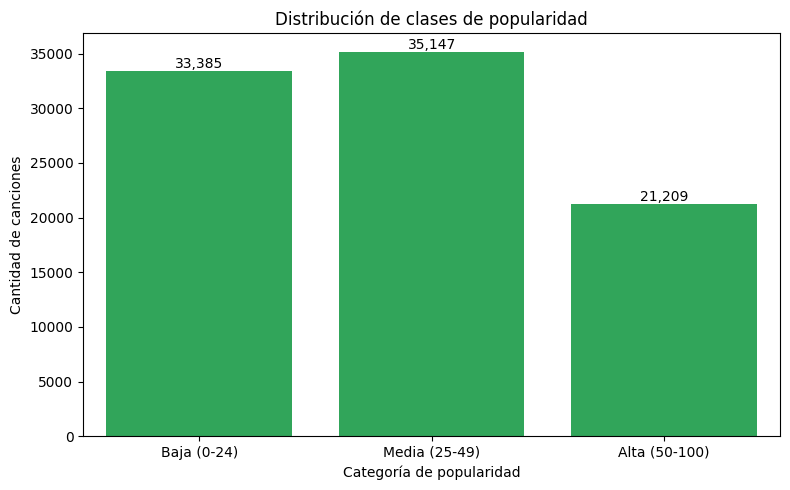

In [ ]:
# PASO 1: Clasificación de popularidad en tres categorías

# Crear nueva variable objetivo sin alterar popularity
df['popularidad_clase'] = pd.cut(
    df['popularity'],
    bins=[-1, 24, 49, 100],
    labels=[0, 1, 2]
).astype(int)

# Nombres descriptivos de las clases
nombres_clases = [
    'Baja (0-24)',
    'Media (25-49)',
    'Alta (50-100)'
]

# Comprobar distribución absoluta y porcentual
distribucion = (
    df['popularidad_clase']
    .value_counts()
    .sort_index()
    .to_frame(name='Cantidad')
)

distribucion['Porcentaje'] = (
    distribucion['Cantidad'] / len(df) * 100
).round(2)

distribucion.index = nombres_clases

print("Distribución de popularidad por categorías:")
display(distribucion)

# Visualizar distribución de clases
plt.figure(figsize=(8, 5))

ax = sns.countplot(
    data=df,
    x='popularidad_clase',
    order=[0, 1, 2],
    color='#1DB954'
)

ax.set_xticks([0, 1, 2])
ax.set_xticklabels(nombres_clases)

plt.title('Distribución de clases de popularidad')
plt.xlabel('Categoría de popularidad')
plt.ylabel('Cantidad de canciones')

for barra in ax.patches:
    altura = barra.get_height()
    ax.annotate(
        f'{int(altura):,}',
        (barra.get_x() + barra.get_width() / 2, altura),
        ha='center',
        va='bottom'
    )

plt.tight_layout()
plt.show()

### 3.7 Selección de variables de la tarea multiclase

Se mantiene la selección coherente con el EDA; revisar en pantalla qué predictores pasan al modelo.


In [ ]:
# PASO 2: Definir X e y para clasificación

# Target categórico
y = df['popularidad_clase']

# Variables descartadas según el EDA previo
columns_to_drop = [
    'Unnamed: 0',
    'track_id',
    'artists',
    'album_name',
    'track_name',
    'energy',
    'popularity',
    'popularidad_clase'
]

# Matriz de predictores
X = df.drop(
    columns=columns_to_drop,
    errors='ignore'
)

# Variables categóricas
categorical_features = [
    'explicit',
    'key',
    'mode',
    'time_signature',
    'track_genre'
]

# Variables numéricas
numerical_features = [
    'duration_ms',
    'danceability',
    'loudness',
    'speechiness',
    'acousticness',
    'instrumentalness',
    'liveness',
    'valence',
    'tempo'
]

print("Dimensión de X:", X.shape)
print("Dimensión de y:", y.shape)

print("\nVariables predictoras:")
print(X.columns.tolist())

print("\nClases del target:")
print(y.value_counts().sort_index())

Dimensión de X: (89741, 14)
Dimensión de y: (89741,)

Variables predictoras:
['duration_ms', 'explicit', 'danceability', 'key', 'loudness', 'mode', 'speechiness', 'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo', 'time_signature', 'track_genre']

Clases del target:
popularidad_clase
0    33385
1    35147
2    21209
Name: count, dtype: int64


### 3.8 Partición estratificada de la tarea principal

La partición 80/20 se realiza antes del ajuste de transformaciones supervisadas. `random_state=42` permite repetirla.


In [ ]:
# PASO 3: División de datos estratificada

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Registros de entrenamiento:", len(X_train))
print("Registros de prueba:", len(X_test))

# Comprobar proporciones
print("\nDistribución porcentual en TRAIN:")
print(
    y_train.value_counts(normalize=True)
    .sort_index()
    .mul(100)
    .round(2)
)

print("\nDistribución porcentual en TEST:")
print(
    y_test.value_counts(normalize=True)
    .sort_index()
    .mul(100)
    .round(2)
)

Registros de entrenamiento: 71792
Registros de prueba: 17949

Distribución porcentual en TRAIN:
popularidad_clase
0    37.20
1    39.16
2    23.63
Name: proportion, dtype: float64

Distribución porcentual en TEST:
popularidad_clase
0    37.20
1    39.17
2    23.63
Name: proportion, dtype: float64


### 3.9 ColumnTransformer multiclase

Se deja `TargetEncoder` dentro de los pipelines para proteger el conjunto de prueba y los folds externos de validación cruzada.


In [ ]:
# PASO 4: Preprocesamiento conservando outliers

# Variables categóricas nominales
categorical_features = [
    'key',
    'time_signature'
]
high_cardinality_features = ['track_genre']

# Variables binarias
binary_features = [
    'explicit',
    'mode'
]

# Preprocesador
preprocessor = ColumnTransformer(
    transformers=[
        (
            'num',
            'passthrough',
            numerical_features
        ),
        (
            'cat',
            OneHotEncoder(
                handle_unknown='ignore',
                sparse_output=False
            ),
            categorical_features
        ),
        ('genre_target', crear_target_encoder(), high_cardinality_features),
        (
            'bin',
            'passthrough',
            binary_features
        )
    ],
    remainder='drop'
)

print("Preprocesador configurado correctamente.")
print("Outliers: conservados")
print("Variables numéricas: sin escalamiento")
print("Categóricas bajas: OneHotEncoder; track_genre: TargetEncoder")

Preprocesador configurado correctamente.
Outliers: conservados
Variables numéricas: sin escalamiento
Categóricas bajas: OneHotEncoder; track_genre: TargetEncoder


### 3.10 Comprobación de las clases

Preparación compartida por los clasificadores Random Forest.


In [ ]:
# ============================================================
# PASO 1: IMPORTACIÓN DE LIBRERÍAS Y VALIDACIÓN
# ============================================================
# Se utilizan los mismos conjuntos y el mismo preprocesador
# que en DecisionTreeClassifier para asegurar una comparación
# metodológicamente justa.

# Nombres de las clases
class_names = [
    'Baja',
    'Media',
    'Alta'
]

# Comprobar que el objetivo sigue siendo multiclase
print("Clases en entrenamiento:")
print(pd.Series(y_train).value_counts().sort_index())

print("\nClases en prueba:")
print(pd.Series(y_test).value_counts().sort_index())

assert set(np.unique(y_train)) == {0, 1, 2}, \
    "y_train debe contener las clases 0, 1 y 2."

assert set(np.unique(y_test)) == {0, 1, 2}, \
    "y_test debe contener las clases 0, 1 y 2."

print("\nDimensiones:")
print("X_train:", X_train.shape)
print("X_test :", X_test.shape)

Clases en entrenamiento:
popularidad_clase
0    26708
1    28117
2    16967
Name: count, dtype: int64

Clases en prueba:
popularidad_clase
0    6677
1    7030
2    4242
Name: count, dtype: int64

Dimensiones:
X_train: (71792, 14)
X_test : (17949, 14)


---
# Fase 4 · Modelado

Se entrenan **dos familias supervisadas**: Decision Tree (árbol individual) y Random Forest (ensamble de árboles por *bagging*), incluyendo versiones base y búsqueda de hiperparámetros. La métrica de optimización para tres clases es **F1 macro**, que da igual peso a las categorías baja, media y alta.

El experimento binario es una referencia didáctica; la selección empresarial se fundamenta en la **tarea multiclase**. Los informes de prueba que imprimen algunas celdas de ajuste se conservan por compatibilidad con las salidas originales, mientras que el análisis comparativo se concentra en la Fase 5.


### 4.1 Árbol binario auxiliar

Entrenamiento sin búsqueda de hiperparámetros; sirve para entender el efecto de trabajar con solo dos clases.


In [ ]:
# ============================================================
# PASO 4: ÁRBOL DE DECISIÓN BINARIO
# ============================================================
# Se entrena un único DecisionTreeClassifier sin búsqueda
# ni ajuste de hiperparámetros.
#
# Se utiliza el pipeline con outliers para mantener la misma
# metodología de preprocesamiento del trabajo original.

# Construir pipeline
dt_bin = Pipeline(
    steps=[
        ('preprocessor', preprocessor_bin),
        ('classifier', DecisionTreeClassifier(
            random_state=42
        ))
    ]
)

# Entrenamiento
dt_bin.fit(X_train_bin, y_train_bin)

# Predicciones sobre el conjunto de prueba
y_pred_bin = dt_bin.predict(X_test_bin)

# Predicciones de entrenamiento para analizar generalización
y_pred_train_bin = dt_bin.predict(X_train_bin)

print("Árbol de decisión binario entrenado correctamente.")

Árbol de decisión binario entrenado correctamente.


### 4.2 Árbol multiclase base

Modelo de referencia; se conservan sus métricas impresas y predicciones para las comparaciones posteriores.


In [ ]:
# PASO 5: Entrenamiento del árbol base

modelo_base = Pipeline(
    steps=[
        ('preprocessor', clone(preprocessor)),
        ('classifier', DecisionTreeClassifier(
            random_state=42
        ))
    ]
)

# Entrenar modelo base
modelo_base.fit(X_train, y_train)

# Predicciones sobre entrenamiento y prueba
y_pred_train_base = modelo_base.predict(X_train)
y_pred_base = modelo_base.predict(X_test)

# Métricas de entrenamiento
f1_train_base = f1_score(
    y_train,
    y_pred_train_base,
    average='macro',
    zero_division=0
)

# Métricas de prueba
accuracy_base = accuracy_score(y_test, y_pred_base)

precision_base = precision_score(
    y_test, y_pred_base,
    average='macro',
    zero_division=0
)

recall_base = recall_score(
    y_test, y_pred_base,
    average='macro',
    zero_division=0
)

f1_base = f1_score(
    y_test, y_pred_base,
    average='macro',
    zero_division=0
)

print("=== DECISION TREE BASE ===")
print(f"Accuracy TEST : {accuracy_base:.4f}")
print(f"Precision TEST: {precision_base:.4f}")
print(f"Recall TEST   : {recall_base:.4f}")
print(f"F1 Macro TEST : {f1_base:.4f}")

print(f"\nF1 Macro TRAIN: {f1_train_base:.4f}")

print("\nReporte por clase:")
print(
    classification_report(
        y_test,
        y_pred_base,
        labels=[0, 1, 2],
        target_names=nombres_clases,
        zero_division=0
    )
)

=== DECISION TREE BASE ===
Accuracy TEST : 0.6238
Precision TEST: 0.6111
Recall TEST   : 0.6117
F1 Macro TEST : 0.6114

F1 Macro TRAIN: 0.9272

Reporte por clase:
               precision    recall  f1-score   support

  Baja (0-24)       0.69      0.70      0.70      6677
Media (25-49)       0.62      0.61      0.61      7030
Alta (50-100)       0.52      0.52      0.52      4242

     accuracy                           0.62     17949
    macro avg       0.61      0.61      0.61     17949
 weighted avg       0.62      0.62      0.62     17949



### 4.3 Optimización del árbol · GridSearchCV

Búsqueda con cuatro folds estratificados y F1 macro. No utiliza el conjunto de prueba para ajustar parámetros.


In [ ]:
# PASO 6: Optimización mediante GridSearchCV

# Crear pipeline del modelo a optimizar
modelo_grid = Pipeline(
    steps=[
        ('preprocessor', clone(preprocessor)),
        ('classifier', DecisionTreeClassifier(
            random_state=42
        ))
    ]
)

# Combinaciones de hiperparámetros
param_grid = {
    'classifier__max_depth': [8, 16, None],
    'classifier__min_samples_split': [2, 20],
    'classifier__min_samples_leaf': [1, 10],
    'classifier__criterion': ['gini', 'entropy']
}

# Validación cruzada estratificada
cv = StratifiedKFold(
    n_splits=4,
    shuffle=True,
    random_state=42
)

# Configuración de GridSearchCV
grid_search = GridSearchCV(
    estimator=modelo_grid,
    param_grid=param_grid,
    scoring='f1_macro',
    cv=cv,
    n_jobs=-1,
    refit=True,
    verbose=1,
    error_score='raise',
    return_train_score=True
)

# Buscar hiperparámetros usando SOLO entrenamiento
grid_search.fit(X_train, y_train)

print("\n=== MEJORES HIPERPARÁMETROS ===")
print(grid_search.best_params_)

print("\nMejor F1 Macro en validación cruzada:")
print(f"{grid_search.best_score_:.4f}")

Fitting 4 folds for each of 24 candidates, totalling 96 fits

=== MEJORES HIPERPARÁMETROS ===
{'classifier__criterion': 'entropy', 'classifier__max_depth': 8, 'classifier__min_samples_leaf': 1, 'classifier__min_samples_split': 2}

Mejor F1 Macro en validación cruzada:
0.6447


### 4.4 Random Forest base

Ensamble de múltiples árboles, con la misma partición y el mismo preprocesamiento que el árbol multiclase.


In [ ]:
# ============================================================
# PASO 2: RANDOM FOREST BASE
# ============================================================
# Se utiliza RandomForestClassifier con sus hiperparámetros
# predictivos predeterminados, sin optimización previa.
#
# El preprocesador conserva los outliers y transforma las
# variables categóricas tal como en DecisionTreeClassifier.
#
# Se integra dentro del Pipeline para que las transformaciones
# se ajusten exclusivamente con los datos de entrenamiento.

rf_base = Pipeline(
    steps=[
        ('preprocessor', preprocessor),
        ('classifier', RandomForestClassifier(
            random_state=42,
            n_jobs=-1
        ))
    ]
)

# Entrenamiento
rf_base.fit(X_train, y_train)

# Predicciones
y_pred_rf_base = rf_base.predict(X_test)

# Predicciones sobre entrenamiento para analizar sobreajuste
y_pred_rf_base_train = rf_base.predict(X_train)

print("Random Forest base entrenado correctamente.")

Random Forest base entrenado correctamente.


### 4.5 Optimización del ensamble · RandomizedSearchCV

Explora diez configuraciones con tres folds estratificados; el ganador se reajusta sobre Train. La CV posterior no es una validación externa independiente del tuning.


In [ ]:
# ============================================================
# PASO 5: OPTIMIZACIÓN CON RANDOMIZEDSEARCHCV
# ============================================================
# Se busca mejorar la generalización del Random Forest.
#
# La validación cruzada es estratificada para mantener la
# proporción de las tres categorías de popularidad.
#
# Se optimiza F1 Macro para dar igual importancia a todas
# las clases, independientemente de su frecuencia.
#
# El preprocesamiento permanece dentro del Pipeline para
# evitar fuga de información durante la validación cruzada.

rf_pipeline = Pipeline(
    steps=[
        ('preprocessor', preprocessor),
        ('classifier', RandomForestClassifier(
            random_state=42,
            n_jobs=1
        ))
    ]
)

# Espacio de búsqueda de hiperparámetros
param_distributions = {
    'classifier__n_estimators': [150, 250, 350],
    'classifier__max_depth': [10, 20, 30, None],
    'classifier__min_samples_split': [2, 5, 10],
    'classifier__min_samples_leaf': [1, 2, 4],
    'classifier__max_features': ['sqrt', 0.5],
    'classifier__class_weight': [None, 'balanced']
}

# Validación cruzada estratificada
cv_rf = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

# Búsqueda aleatoria
random_search_rf = RandomizedSearchCV(
    estimator=rf_pipeline,
    param_distributions=param_distributions,
    n_iter=10,
    scoring='f1_macro',
    cv=cv_rf,
    random_state=42,
    n_jobs=-1,
    verbose=1,
    return_train_score=True,
    refit=True
)

# Ajustar utilizando únicamente el conjunto de entrenamiento
random_search_rf.fit(X_train, y_train)

# Recuperar el mejor pipeline completo
rf_optimizado = random_search_rf.best_estimator_

print("\nMejores hiperparámetros:")
for parametro, valor in random_search_rf.best_params_.items():
    print(f"{parametro}: {valor}")

print(
    f"\nMejor F1 Macro promedio en CV: "
    f"{random_search_rf.best_score_:.4f}"
)

Fitting 3 folds for each of 10 candidates, totalling 30 fits


/usr/local/lib/python3.13/dist-packages/joblib/externals/loky/process_executor.py:787: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(



Mejores hiperparámetros:
classifier__n_estimators: 150
classifier__min_samples_split: 2
classifier__min_samples_leaf: 2
classifier__max_features: 0.5
classifier__max_depth: None
classifier__class_weight: balanced

Mejor F1 Macro promedio en CV: 0.6918


---
# Fase 5 · Evaluación de los modelos y decisión

Se reúnen los diagnósticos del experimento binario, la comparación principal, la generalización del ensamble, el análisis ROC para popularidad alta y la traducción de los errores a decisiones comerciales.

**Precaución metodológica:** las métricas Train/Test y la validación cruzada describen el rendimiento observado; no prueban resultados futuros. La comparación económica emplea parámetros hipotéticos. Ajustar una política con resultados del conjunto de prueba produciría conclusiones excesivamente optimistas.


### 5.1 Árbol binario · accuracy, precision, recall y F1

Solo para la tarea 0–33 vs. 34–100.


In [ ]:
# ============================================================
# PASO 5: MÉTRICAS DE CLASIFICACIÓN BINARIA
# ============================================================
# Accuracy, Precision, Recall y F1-score.
#
# Se considera como clase positiva:
# 1 = Alta popularidad.
#
# Esto permite evaluar específicamente qué tan bien
# identifica el modelo las canciones del grupo alto.

accuracy_bin = accuracy_score(
    y_test_bin, y_pred_bin
)

precision_bin = precision_score(
    y_test_bin, y_pred_bin,
    pos_label=1,
    zero_division=0
)

recall_bin = recall_score(
    y_test_bin, y_pred_bin,
    pos_label=1,
    zero_division=0
)

f1_bin = f1_score(
    y_test_bin, y_pred_bin,
    pos_label=1,
    zero_division=0
)

# Tabla de métricas
metricas_bin = pd.DataFrame({
    'Métrica': [
        'Accuracy',
        'Precision',
        'Recall',
        'F1-score'
    ],
    'Valor': [
        accuracy_bin,
        precision_bin,
        recall_bin,
        f1_bin
    ]
})

print("=== MÉTRICAS DEL ÁRBOL BINARIO ===")
display(metricas_bin.round(4))

# Reporte adicional por categoría
print("\n=== REPORTE POR CLASE ===")

print(
    classification_report(
        y_test_bin,
        y_pred_bin,
        labels=[0, 1],
        target_names=[
            'Baja popularidad',
            'Alta popularidad'
        ],
        zero_division=0
    )
)

=== MÉTRICAS DEL ÁRBOL BINARIO ===


,Métrica,Valor
0,Accuracy,0.7493
1,Precision,0.7470
2,Recall,0.7492
3,F1-score,0.7481



=== REPORTE POR CLASE ===
                  precision    recall  f1-score   support

Baja popularidad       0.75      0.75      0.75      9032
Alta popularidad       0.75      0.75      0.75      8917

        accuracy                           0.75     17949
       macro avg       0.75      0.75      0.75     17949
    weighted avg       0.75      0.75      0.75     17949



### 5.2 Árbol binario · matriz de confusión

Muestra aciertos y errores de las dos clases.


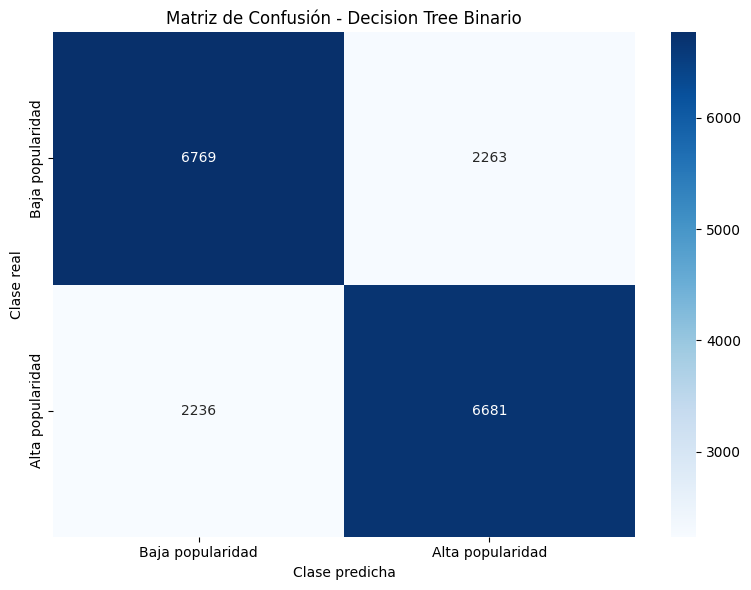

In [ ]:
# ============================================================
# PASO 6: MATRIZ DE CONFUSIÓN BINARIA
# ============================================================
# Permite identificar verdaderos negativos, falsos positivos,
# falsos negativos y verdaderos positivos.
#
# Clase 0 = Baja popularidad
# Clase 1 = Alta popularidad


cm_bin = confusion_matrix(
    y_test_bin,
    y_pred_bin,
    labels=[0, 1]
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm_bin,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=[
        'Baja popularidad',
        'Alta popularidad'
    ],
    yticklabels=[
        'Baja popularidad',
        'Alta popularidad'
    ]
)

plt.title('Matriz de Confusión - Decision Tree Binario')
plt.xlabel('Clase predicha')
plt.ylabel('Clase real')
plt.tight_layout()
plt.show()

### 5.3 Interpretación comercial del experimento binario

Distinguir falsos positivos, que gastan recursos de revisión, y falsos negativos, que dejan canciones sin detectar.


In [ ]:
# ============================================================
# PASO 7: INTERPRETACIÓN DE LA MATRIZ DE CONFUSIÓN
# ============================================================
# Se extraen los cuatro resultados de la matriz y se
# interpretan según el objetivo comercial.

vn, fp, fn, vp = cm_bin.ravel()

print("=== INTERPRETACIÓN DE RESULTADOS ===")

print(f"\nVerdaderos Negativos (VN): {vn}")
print(
    f"El modelo identificó correctamente {vn} canciones "
    "de baja popularidad."
)

print(f"\nFalsos Positivos (FP): {fp}")
print(
    f"El modelo clasificó {fp} canciones de baja "
    "popularidad como si fueran de alta popularidad."
)

print(f"\nFalsos Negativos (FN): {fn}")
print(
    f"El modelo no consiguió identificar {fn} canciones "
    "que realmente pertenecían al grupo de alta popularidad."
)

print(f"\nVerdaderos Positivos (VP): {vp}")
print(
    f"El modelo identificó correctamente {vp} canciones "
    "de alta popularidad."
)

print("\n=== RESUMEN COMERCIAL ===")
print(f"Accuracy: {accuracy_bin:.2%}")
print(f"Precision: {precision_bin:.2%}")
print(f"Recall: {recall_bin:.2%}")
print(f"F1-score: {f1_bin:.2%}")

=== INTERPRETACIÓN DE RESULTADOS ===

Verdaderos Negativos (VN): 6769
El modelo identificó correctamente 6769 canciones de baja popularidad.

Falsos Positivos (FP): 2263
El modelo clasificó 2263 canciones de baja popularidad como si fueran de alta popularidad.

Falsos Negativos (FN): 2236
El modelo no consiguió identificar 2236 canciones que realmente pertenecían al grupo de alta popularidad.

Verdaderos Positivos (VP): 6681
El modelo identificó correctamente 6681 canciones de alta popularidad.

=== RESUMEN COMERCIAL ===
Accuracy: 74.93%
Precision: 74.70%
Recall: 74.92%
F1-score: 74.81%


### 5.4 Generalización del árbol binario

Comparación entre entrenamiento y prueba; un F1 alto en Train junto con una brecha grande indica sobreajuste.


In [ ]:
# ============================================================
# PASO 8: ANÁLISIS DEL POSIBLE SOBREAJUSTE
# ============================================================
# Se comparan métricas de entrenamiento y prueba.
#
# Una diferencia considerable puede indicar que el árbol
# memorizó patrones específicos de entrenamiento y no
# generaliza adecuadamente.

metricas_train_test_bin = pd.DataFrame({
    'Métrica': [
        'Accuracy',
        'F1-score'
    ],
    'Entrenamiento': [
        accuracy_score(
            y_train_bin,
            y_pred_train_bin
        ),
        f1_score(
            y_train_bin,
            y_pred_train_bin
        )
    ],
    'Prueba': [
        accuracy_bin,
        f1_bin
    ]
})

metricas_train_test_bin['Brecha'] = (
    metricas_train_test_bin['Entrenamiento']
    - metricas_train_test_bin['Prueba']
)

display(metricas_train_test_bin.round(4))

,Métrica,Entrenamiento,Prueba,Brecha
0,Accuracy,0.9650,0.7493,0.2157
1,F1-score,0.9647,0.7481,0.2166


### 5.5 Árbol multiclase optimizado · predicciones

Recupera el mejor estimador seleccionado con GridSearchCV y calcula métricas del mismo Test reservado.


In [ ]:
# PASO 7: Evaluación del modelo optimizado

# Recuperar el mejor pipeline completo
modelo_optimizado = grid_search.best_estimator_

# Predicciones
y_pred_train_opt = modelo_optimizado.predict(X_train)
y_pred_opt = modelo_optimizado.predict(X_test)

# F1 entrenamiento
f1_train_opt = f1_score(
    y_train,
    y_pred_train_opt,
    average='macro',
    zero_division=0
)

# Métricas en prueba
accuracy_opt = accuracy_score(y_test, y_pred_opt)

precision_opt = precision_score(
    y_test, y_pred_opt,
    average='macro',
    zero_division=0
)

recall_opt = recall_score(
    y_test, y_pred_opt,
    average='macro',
    zero_division=0
)

f1_opt = f1_score(
    y_test, y_pred_opt,
    average='macro',
    zero_division=0
)

print("=== DECISION TREE OPTIMIZADO ===")

print(f"Accuracy TEST : {accuracy_opt:.4f}")
print(f"Precision TEST: {precision_opt:.4f}")
print(f"Recall TEST   : {recall_opt:.4f}")
print(f"F1 Macro TEST : {f1_opt:.4f}")

print(f"\nF1 Macro TRAIN: {f1_train_opt:.4f}")

print("\nReporte por clase:")
print(
    classification_report(
        y_test,
        y_pred_opt,
        labels=[0, 1, 2],
        target_names=nombres_clases,
        zero_division=0
    )
)

=== DECISION TREE OPTIMIZADO ===
Accuracy TEST : 0.6614
Precision TEST: 0.6490
Recall TEST   : 0.6414
F1 Macro TEST : 0.6435

F1 Macro TRAIN: 0.6561

Reporte por clase:
               precision    recall  f1-score   support

  Baja (0-24)       0.71      0.77      0.74      6677
Media (25-49)       0.65      0.66      0.66      7030
Alta (50-100)       0.59      0.50      0.54      4242

     accuracy                           0.66     17949
    macro avg       0.65      0.64      0.64     17949
 weighted avg       0.66      0.66      0.66     17949



### 5.6 Comprobación de dimensionalidad de Target Encoding

Permite verificar cuántas características se obtienen al codificar `track_genre` en tres clases.


In [ ]:
"""Audita la dimensionalidad de TargetEncoder sin reajustar ni filtrar el test.

Se consultan los nombres del preprocesador del árbol YA entrenado en X_train.
En el caso multiclase, el género origina una columna por clase.
Esta comprobación describe el codificador: NO demuestra mejor precisión.
"""
preprocesador_te = modelo_optimizado.named_steps['preprocessor']
variables_transformadas_te = preprocesador_te.get_feature_names_out()
nombres_genero_te = [
    nombre for nombre in variables_transformadas_te
    if nombre.startswith('genre_target__')
]

print('Géneros diferentes observados en TRAIN:', X_train['track_genre'].nunique(dropna=False))
print('Clases observadas en TRAIN:', sorted(y_train.unique().tolist()))
print('Columnas generadas por TargetEncoder para el género:', len(nombres_genero_te))
print('Nombres de columnas del género:', nombres_genero_te)
print('Total de columnas transformadas:', len(variables_transformadas_te))
assert len(nombres_genero_te) == len(np.unique(y_train)), (
    'La salida esperada de TargetEncoder multiclase debe ser una columna por clase.'
)

Géneros diferentes observados en TRAIN: 113
Clases observadas en TRAIN: [0, 1, 2]
Columnas generadas por TargetEncoder para el género: 3
Nombres de columnas del género: ['genre_target__track_genre_0', 'genre_target__track_genre_1', 'genre_target__track_genre_2']
Total de columnas transformadas: 31


### 5.7 Árbol base vs. árbol optimizado

Medir mejora de F1 macro y reducción de brecha Train–Test bajo la misma codificación.


=== COMPARACIÓN DE MODELOS ===


,Métrica,Árbol Base,Árbol Optimizado,Diferencia
0,Accuracy,0.6238,0.6614,0.0377
1,Precision Macro,0.6111,0.6490,0.0378
2,Recall Macro,0.6117,0.6414,0.0297
3,F1 Macro,0.6114,0.6435,0.0321



=== ANÁLISIS DE GENERALIZACIÓN ===


,Modelo,F1 Train,F1 Test,Brecha Train-Test
0,Base,0.9272,0.6114,0.3158
1,Optimizado,0.6561,0.6435,0.0126


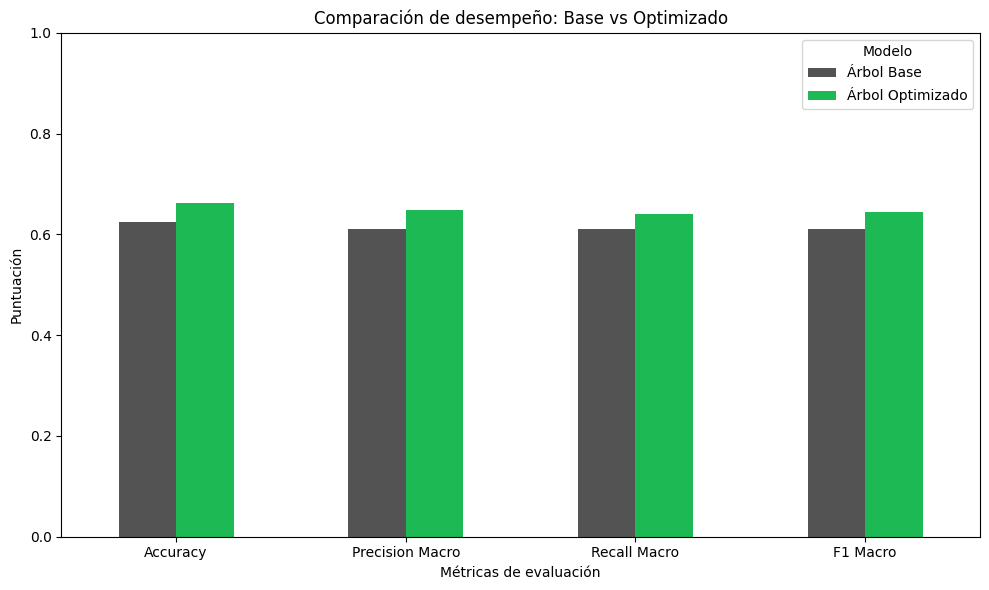

In [ ]:
# PASO 8: Comparación de métricas

comparacion = pd.DataFrame({
    'Métrica': [
        'Accuracy',
        'Precision Macro',
        'Recall Macro',
        'F1 Macro'
    ],
    'Árbol Base': [
        accuracy_base,
        precision_base,
        recall_base,
        f1_base
    ],
    'Árbol Optimizado': [
        accuracy_opt,
        precision_opt,
        recall_opt,
        f1_opt
    ]
})

comparacion['Diferencia'] = (
    comparacion['Árbol Optimizado'] -
    comparacion['Árbol Base']
)

print("=== COMPARACIÓN DE MODELOS ===")
display(comparacion.round(4))

# Comparación de sobreajuste
comparacion_overfitting = pd.DataFrame({
    'Modelo': ['Base', 'Optimizado'],
    'F1 Train': [f1_train_base, f1_train_opt],
    'F1 Test': [f1_base, f1_opt]
})

comparacion_overfitting['Brecha Train-Test'] = (
    comparacion_overfitting['F1 Train'] -
    comparacion_overfitting['F1 Test']
)

print("\n=== ANÁLISIS DE GENERALIZACIÓN ===")
display(comparacion_overfitting.round(4))

# Gráfico de métricas
comparacion_grafico = comparacion.set_index('Métrica')[
    ['Árbol Base', 'Árbol Optimizado']
]

comparacion_grafico.plot(
    kind='bar',
    figsize=(10, 6),
    color=['#535353', '#1DB954']
)

plt.title('Comparación de desempeño: Base vs Optimizado')
plt.xlabel('Métricas de evaluación')
plt.ylabel('Puntuación')
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(title='Modelo')
plt.tight_layout()
plt.show()

### 5.8 Matrices de confusión · árboles

Prestar atención a las confusiones entre baja, media y alta popularidad.


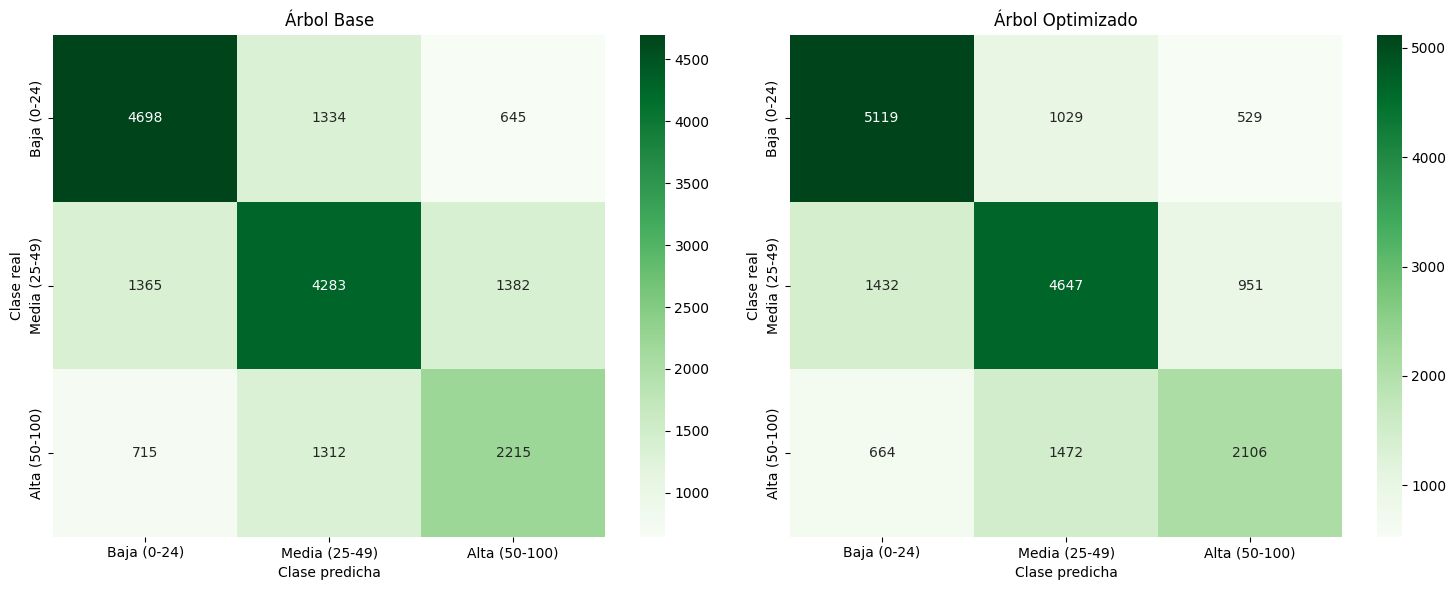

In [ ]:
# PASO 9: Matrices de confusión comparativas

fig, axes = plt.subplots(
    1, 2,
    figsize=(15, 6)
)

modelos = [
    ('Árbol Base', y_pred_base),
    ('Árbol Optimizado', y_pred_opt)
]

for ax, (titulo, predicciones) in zip(axes, modelos):

    matriz = confusion_matrix(
        y_test,
        predicciones,
        labels=[0, 1, 2]
    )

    sns.heatmap(
        matriz,
        annot=True,
        fmt='d',
        cmap='Greens',
        xticklabels=nombres_clases,
        yticklabels=nombres_clases,
        ax=ax
    )

    ax.set_title(titulo)
    ax.set_xlabel('Clase predicha')
    ax.set_ylabel('Clase real')

plt.tight_layout()
plt.show()

### 5.9 Interpretación de variables del árbol

La importancia describe asociaciones usadas en las particiones del modelo: **no** es causalidad.


=== TOP 15 VARIABLES MÁS IMPORTANTES ===


,Variable,Importancia
26,genre_target__track_genre_0,0.571767
28,genre_target__track_genre_2,0.176677
27,genre_target__track_genre_1,0.142418
4,num__acousticness,0.017707
2,num__loudness,0.014650
7,num__valence,0.013778
3,num__speechiness,0.013654
5,num__instrumentalness,0.013501
0,num__duration_ms,0.011485
29,bin__explicit,0.006827


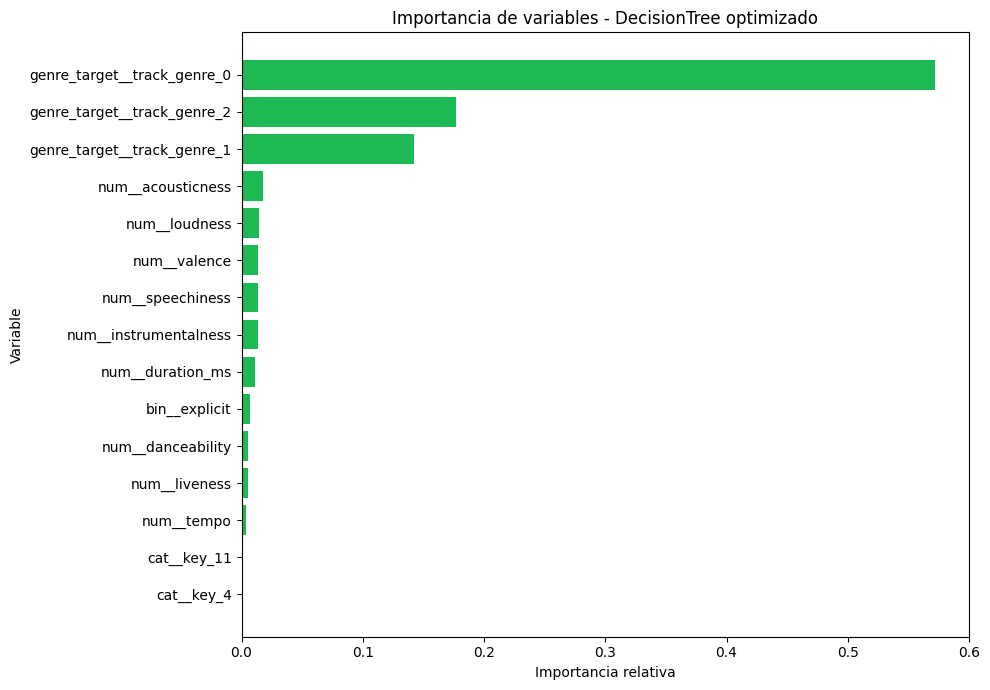

In [ ]:
# PASO 10: Importancia de variables del árbol optimizado

# Recuperar el preprocesador entrenado
preprocesador_entrenado = (
    modelo_optimizado.named_steps['preprocessor']
)

# Recuperar el árbol entrenado
arbol_optimizado = (
    modelo_optimizado.named_steps['classifier']
)

# Obtener nombres de características transformadas
nombres_variables = (
    preprocesador_entrenado.get_feature_names_out()
)

# Obtener importancia de cada característica
importancias = pd.DataFrame({
    'Variable': nombres_variables,
    'Importancia': arbol_optimizado.feature_importances_
})

# Ordenar de mayor a menor importancia
importancias = importancias.sort_values(
    by='Importancia',
    ascending=False
)

print("=== TOP 15 VARIABLES MÁS IMPORTANTES ===")
display(importancias.head(15))

# Visualización
top_importancias = importancias.head(15).sort_values(
    by='Importancia',
    ascending=True
)

plt.figure(figsize=(10, 7))

plt.barh(
    top_importancias['Variable'],
    top_importancias['Importancia'],
    color='#1DB954'
)

plt.title('Importancia de variables - DecisionTree optimizado')
plt.xlabel('Importancia relativa')
plt.ylabel('Variable')
plt.tight_layout()
plt.show()

### 5.10 Diagnóstico final del árbol

Valorar conjuntamente F1 de prueba y sobreajuste; un mejor ajuste a Train no garantiza buenas predicciones.


In [ ]:
# PASO 11: Diagnóstico final de los modelos

diferencia_f1 = f1_opt - f1_base

brecha_base = f1_train_base - f1_base
brecha_opt = f1_train_opt - f1_opt

print("=== DIAGNÓSTICO FINAL ===")

print(f"F1 Macro Base: {f1_base:.4f}")
print(f"F1 Macro Optimizado: {f1_opt:.4f}")

print(f"\nCambio en F1 Macro: {diferencia_f1:+.4f}")

print(f"Brecha Base: {brecha_base:.4f}")
print(f"Brecha Optimizado: {brecha_opt:.4f}")

if diferencia_f1 > 0:
    print("\nEl modelo optimizado obtuvo mayor F1 Macro en test.")
    modelo_ganador = modelo_optimizado
    nombre_ganador = "DecisionTree Optimizado"

elif diferencia_f1 < 0:
    print("\nEl modelo base obtuvo mayor F1 Macro en test.")
    modelo_ganador = modelo_base
    nombre_ganador = "DecisionTree Base"

else:
    print("\nAmbos modelos obtuvieron el mismo F1 Macro en test.")
    modelo_ganador = modelo_base
    nombre_ganador = "Empate - Base por simplicidad"

if brecha_opt < brecha_base:
    print("La optimización redujo la brecha Train-Test.")
elif brecha_opt > brecha_base:
    print("La optimización aumentó la brecha Train-Test.")
else:
    print("La brecha Train-Test se mantuvo.")

print(f"\nModelo seleccionado según F1 Macro: {nombre_ganador}")

# Evaluación especial de la clase comercialmente importante
print("\n=== RECALL DE POPULARIDAD ALTA ===")

recall_alta_base = recall_score(
    (y_test == 2).astype(int),
    (y_pred_base == 2).astype(int),
    zero_division=0
)

recall_alta_opt = recall_score(
    (y_test == 2).astype(int),
    (y_pred_opt == 2).astype(int),
    zero_division=0
)

print(f"Recall Alta - Base: {recall_alta_base:.4f}")
print(f"Recall Alta - Optimizado: {recall_alta_opt:.4f}")

=== DIAGNÓSTICO FINAL ===
F1 Macro Base: 0.6114
F1 Macro Optimizado: 0.6435

Cambio en F1 Macro: +0.0321
Brecha Base: 0.3158
Brecha Optimizado: 0.0126

El modelo optimizado obtuvo mayor F1 Macro en test.
La optimización redujo la brecha Train-Test.

Modelo seleccionado según F1 Macro: DecisionTree Optimizado

=== RECALL DE POPULARIDAD ALTA ===
Recall Alta - Base: 0.5222
Recall Alta - Optimizado: 0.4965


### 5.11 Random Forest base · evaluación

Incluye métricas ordinales porque confundir baja con alta es más costoso de interpretar que equivocarse en una clase vecina.


In [ ]:
# ============================================================
# PASO 3: EVALUACIÓN DEL RANDOM FOREST BASE
# ============================================================
# Se utilizan las mismas métricas de clasificación del
# DecisionTreeClassifier para mantener la comparabilidad.
#
# Se incorpora MAE ordinal y Quadratic Weighted Kappa para
# considerar el orden natural de las clases de popularidad.

def evaluar_clasificador(nombre, y_real, y_pred):
    return {
        'Modelo': nombre,
        'Accuracy': accuracy_score(y_real, y_pred),
        'Precision Macro': precision_score(
            y_real, y_pred,
            average='macro',
            zero_division=0
        ),
        'Recall Macro': recall_score(
            y_real, y_pred,
            average='macro',
            zero_division=0
        ),
        'F1 Macro': f1_score(
            y_real, y_pred,
            average='macro',
            zero_division=0
        ),
        'MAE Ordinal': mean_absolute_error(
            y_real, y_pred
        ),
        'Kappa Cuadrático': cohen_kappa_score(
            y_real, y_pred,
            labels=[0, 1, 2],
            weights='quadratic'
        )
    }


# Métricas sobre test
metricas_rf_base = evaluar_clasificador(
    'Random Forest Base',
    y_test,
    y_pred_rf_base
)

display(
    pd.DataFrame([metricas_rf_base]).round(4)
)

# Reporte detallado por clase
print("\nReporte de clasificación:")
print(
    classification_report(
        y_test,
        y_pred_rf_base,
        labels=[0, 1, 2],
        target_names=class_names,
        zero_division=0
    )
)

# Comparación del rendimiento de entrenamiento y prueba
f1_train_rf_base = f1_score(
    y_train,
    y_pred_rf_base_train,
    average='macro',
    zero_division=0
)

f1_test_rf_base = f1_score(
    y_test,
    y_pred_rf_base,
    average='macro',
    zero_division=0
)

print(f"F1 Macro Train: {f1_train_rf_base:.4f}")
print(f"F1 Macro Test : {f1_test_rf_base:.4f}")
print(f"Brecha Train-Test: "
      f"{f1_train_rf_base - f1_test_rf_base:.4f}")

,Modelo,Accuracy,Precision Macro,Recall Macro,F1 Macro,MAE Ordinal,Kappa Cuadrático
0,Random Forest Base,0.7126,0.7047,0.6948,0.6977,0.3414,0.6136



Reporte de clasificación:
              precision    recall  f1-score   support

        Baja       0.74      0.82      0.78      6677
       Media       0.70      0.70      0.70      7030
        Alta       0.67      0.56      0.61      4242

    accuracy                           0.71     17949
   macro avg       0.70      0.69      0.70     17949
weighted avg       0.71      0.71      0.71     17949

F1 Macro Train: 0.9805
F1 Macro Test : 0.6977
Brecha Train-Test: 0.2829


### 5.12 Matrices de confusión · Random Forest base


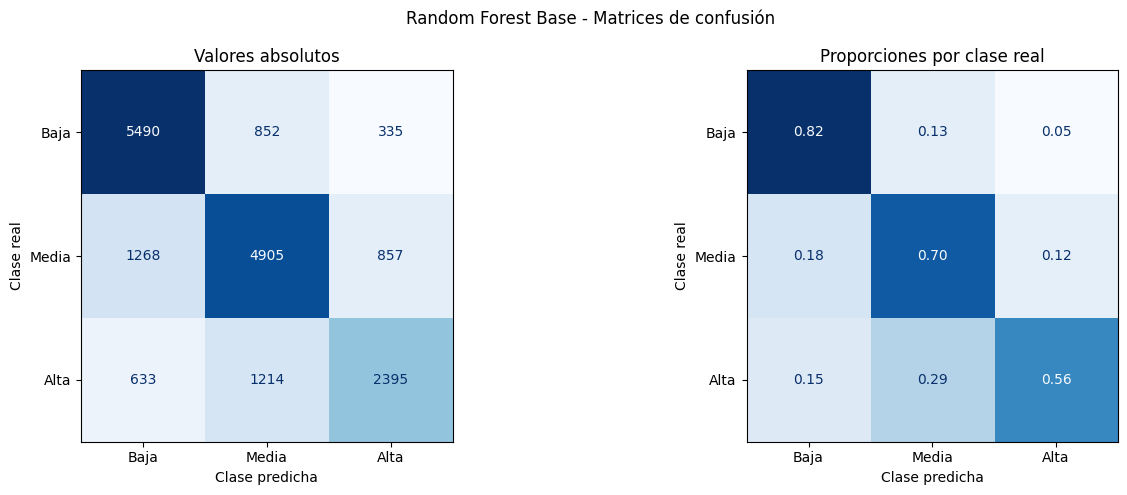

In [ ]:
# ============================================================
# PASO 4: MATRIZ DE CONFUSIÓN - RANDOM FOREST BASE
# ============================================================
# Permite identificar qué clases se confunden y si los
# errores ocurren entre categorías vecinas o extremas.

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, normalize, titulo in [
    (axes[0], None, 'Valores absolutos'),
    (axes[1], 'true', 'Proporciones por clase real')
]:
    ConfusionMatrixDisplay.from_predictions(
        y_test,
        y_pred_rf_base,
        labels=[0, 1, 2],
        display_labels=class_names,
        normalize=normalize,
        cmap='Blues',
        values_format='d' if normalize is None else '.2f',
        ax=ax,
        colorbar=False
    )
    ax.set_title(titulo)
    ax.set_xlabel('Clase predicha')
    ax.set_ylabel('Clase real')

plt.suptitle('Random Forest Base - Matrices de confusión')
plt.tight_layout()
plt.show()

### 5.13 Resultados de la búsqueda aleatoria

Inspeccionar puntaje medio y dispersión en validación cruzada.


In [ ]:
# ============================================================
# PASO 6: RESULTADOS DE LA BÚSQUEDA
# ============================================================
# Se comparan las configuraciones evaluadas mediante
# sus resultados de F1 Macro en validación cruzada.

resultados_busqueda_rf = pd.DataFrame(
    random_search_rf.cv_results_
)

columnas_resultados = [
    'rank_test_score',
    'mean_train_score',
    'mean_test_score',
    'std_test_score',
    'params'
]

display(
    resultados_busqueda_rf[columnas_resultados]
    .sort_values('rank_test_score')
    .head(10)
    .round(4)
)

,rank_test_score,mean_train_score,mean_test_score,std_test_score,params
6,1,0.9506,0.6918,0.0020,"{'classifier__n_estimators': 150, 'classifier_..."
0,2,0.8886,0.6907,0.0006,"{'classifier__n_estimators': 250, 'classifier_..."
9,3,0.9406,0.6903,0.0014,"{'classifier__n_estimators': 250, 'classifier_..."
8,4,0.9213,0.6891,0.0015,"{'classifier__n_estimators': 150, 'classifier_..."
4,5,0.9278,0.6891,0.0013,"{'classifier__n_estimators': 350, 'classifier_..."
7,6,0.8854,0.6886,0.0020,"{'classifier__n_estimators': 250, 'classifier_..."
5,7,0.8907,0.6880,0.0018,"{'classifier__n_estimators': 350, 'classifier_..."
2,8,0.8528,0.6827,0.0025,"{'classifier__n_estimators': 150, 'classifier_..."
1,9,0.8210,0.6810,0.0018,"{'classifier__n_estimators': 150, 'classifier_..."
3,10,0.7066,0.6665,0.0031,"{'classifier__n_estimators': 150, 'classifier_..."


### 5.14 Random Forest optimizado · evaluación

Rendimiento guardado con Target + One-Hot: **F1 macro Test 0,7007**, **F1 macro Train 0,9504**; evaluar el sobreajuste y cada clase.


In [ ]:
# ============================================================
# PASO 7: EVALUACIÓN DEL RANDOM FOREST OPTIMIZADO
# ============================================================
# Se evalúa el mejor modelo sobre el conjunto de prueba,
# que no participó en la optimización.

# Predicciones
y_pred_rf_opt = rf_optimizado.predict(X_test)
y_pred_rf_opt_train = rf_optimizado.predict(X_train)

# Métricas sobre test
metricas_rf_opt = evaluar_clasificador(
    'Random Forest Optimizado',
    y_test,
    y_pred_rf_opt
)

display(
    pd.DataFrame([metricas_rf_opt]).round(4)
)

print("\nReporte de clasificación:")
print(
    classification_report(
        y_test,
        y_pred_rf_opt,
        labels=[0, 1, 2],
        target_names=class_names,
        zero_division=0
    )
)

# Evaluación del posible sobreajuste
f1_train_rf_opt = f1_score(
    y_train,
    y_pred_rf_opt_train,
    average='macro',
    zero_division=0
)

f1_test_rf_opt = f1_score(
    y_test,
    y_pred_rf_opt,
    average='macro',
    zero_division=0
)

print(f"F1 Macro Train: {f1_train_rf_opt:.4f}")
print(f"F1 Macro Test : {f1_test_rf_opt:.4f}")
print(
    f"Brecha Train-Test: "
    f"{f1_train_rf_opt - f1_test_rf_opt:.4f}"
)

,Modelo,Accuracy,Precision Macro,Recall Macro,F1 Macro,MAE Ordinal,Kappa Cuadrático
0,Random Forest Optimizado,0.7129,0.7028,0.7002,0.7007,0.3441,0.6132



Reporte de clasificación:
              precision    recall  f1-score   support

        Baja       0.75      0.81      0.78      6677
       Media       0.72      0.68      0.70      7030
        Alta       0.65      0.60      0.62      4242

    accuracy                           0.71     17949
   macro avg       0.70      0.70      0.70     17949
weighted avg       0.71      0.71      0.71     17949

F1 Macro Train: 0.9504
F1 Macro Test : 0.7007
Brecha Train-Test: 0.2497


### 5.15 Random Forest base vs. optimizado

El beneficio de la optimización es moderado: **F1 macro 0,6977 → 0,7007**. El modelo base puede ser competitivo según presupuesto y criterio de decisión.


,Accuracy,Precision Macro,Recall Macro,F1 Macro,MAE Ordinal,Kappa Cuadrático
Modelo,,,,,,
Random Forest Base,0.7126,0.7047,0.6948,0.6977,0.3414,0.6136
Random Forest Optimizado,0.7129,0.7028,0.7002,0.7007,0.3441,0.6132



Diferencias: optimizado - base


,0
Accuracy,0.0003
Precision Macro,-0.0019
Recall Macro,0.0053
F1 Macro,0.0030
MAE Ordinal,0.0028
Kappa Cuadrático,-0.0004


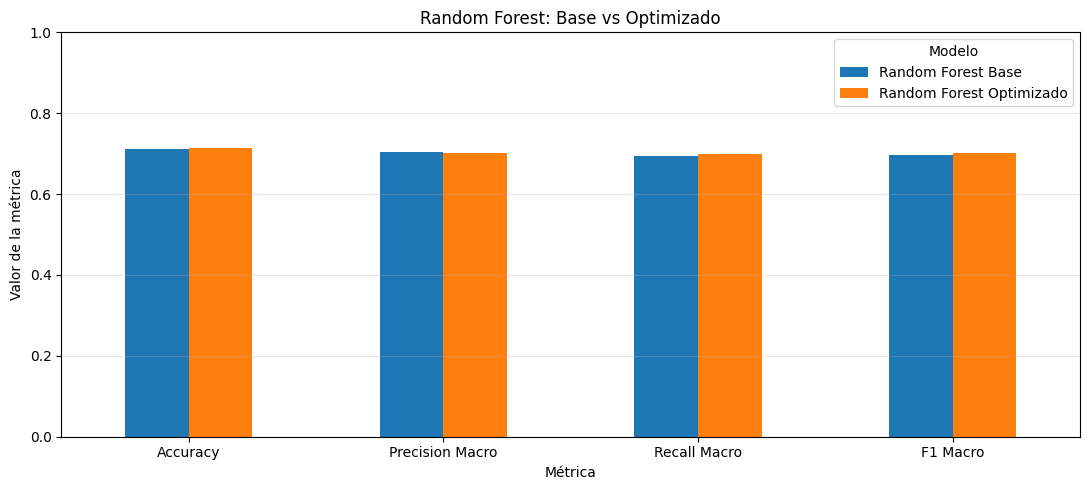

In [ ]:
# ============================================================
# PASO 8: COMPARACIÓN BASE VS OPTIMIZADO
# ============================================================
# Se comparan las métricas obtenidas sobre el mismo conjunto
# de prueba, manteniendo las mismas variables y preprocesamiento.

comparacion_rf = pd.DataFrame([
    metricas_rf_base,
    metricas_rf_opt
]).set_index('Modelo')

display(comparacion_rf.round(4))

# Diferencias del optimizado respecto al base
diferencias_rf = (
    comparacion_rf.loc['Random Forest Optimizado']
    - comparacion_rf.loc['Random Forest Base']
)

print("\nDiferencias: optimizado - base")
display(diferencias_rf.round(4))

# Gráfico de métricas principales
metricas_grafico = [
    'Accuracy',
    'Precision Macro',
    'Recall Macro',
    'F1 Macro'
]

comparacion_rf[metricas_grafico].T.plot(
    kind='bar',
    figsize=(11, 5),
    ylim=(0, 1),
    rot=0
)

plt.title('Random Forest: Base vs Optimizado')
plt.ylabel('Valor de la métrica')
plt.xlabel('Métrica')
plt.legend(title='Modelo')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

### 5.16 Matrices de confusión · Random Forest optimizado


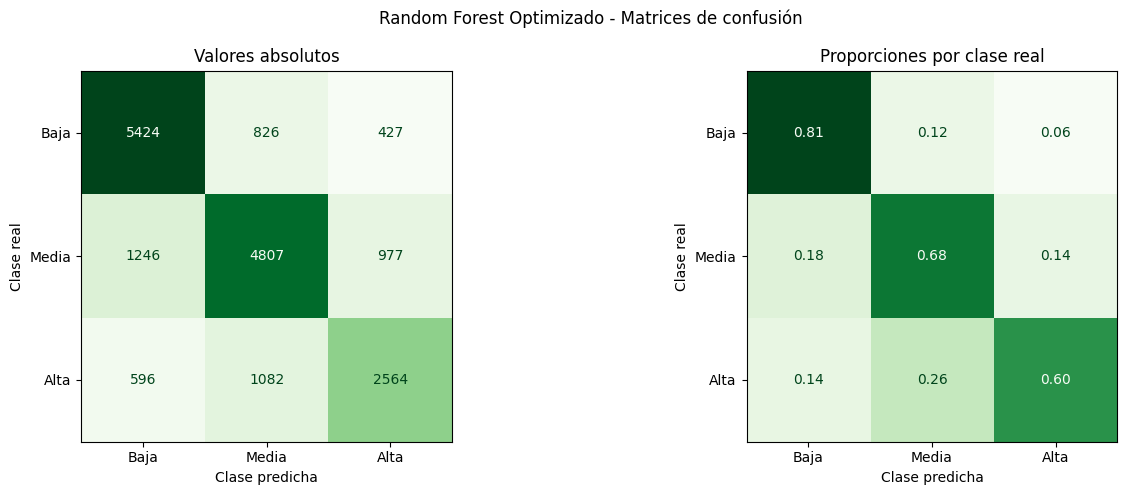

In [ ]:
# ============================================================
# PASO 9: MATRIZ DE CONFUSIÓN - RANDOM FOREST OPTIMIZADO
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, normalize, titulo in [
    (axes[0], None, 'Valores absolutos'),
    (axes[1], 'true', 'Proporciones por clase real')
]:
    ConfusionMatrixDisplay.from_predictions(
        y_test,
        y_pred_rf_opt,
        labels=[0, 1, 2],
        display_labels=class_names,
        normalize=normalize,
        cmap='Greens',
        values_format='d' if normalize is None else '.2f',
        ax=ax,
        colorbar=False
    )
    ax.set_title(titulo)
    ax.set_xlabel('Clase predicha')
    ax.set_ylabel('Clase real')

plt.suptitle('Random Forest Optimizado - Matrices de confusión')
plt.tight_layout()
plt.show()

### 5.17 Comparativa de todos los modelos

Resultado observado: el Random Forest optimizado lidera en F1 macro de prueba **dentro de este notebook**. El modelo One-Hot de otro experimento obtuvo un resultado apenas superior, por lo que no asumir que Target es siempre mejor.


In [ ]:
# ============================================================
# PASO 10: COMPARACIÓN DECISION TREE VS RANDOM FOREST
# ============================================================

metricas_dt_base = evaluar_clasificador(
    'Decision Tree Base',
    y_test,
    y_pred_base
)

metricas_dt_opt = evaluar_clasificador(
    'Decision Tree Optimizado',
    y_test,
    y_pred_opt
)

# Tabla comparativa general
comparacion_modelos = pd.DataFrame([
    metricas_dt_base,
    metricas_dt_opt,
    metricas_rf_base,
    metricas_rf_opt
]).set_index('Modelo')

display(
    comparacion_modelos.round(4)
)

# Ordenar por F1 Macro
ranking_modelos = comparacion_modelos.sort_values(
    by='F1 Macro',
    ascending=False
)

print("\nRanking según F1 Macro:")
display(ranking_modelos.round(4))

,Accuracy,Precision Macro,Recall Macro,F1 Macro,MAE Ordinal,Kappa Cuadrático
Modelo,,,,,,
Decision Tree Base,0.6238,0.6111,0.6117,0.6114,0.4520,0.4902
Decision Tree Optimizado,0.6614,0.6490,0.6414,0.6435,0.4050,0.5343
Random Forest Base,0.7126,0.7047,0.6948,0.6977,0.3414,0.6136
Random Forest Optimizado,0.7129,0.7028,0.7002,0.7007,0.3441,0.6132



Ranking según F1 Macro:


,Accuracy,Precision Macro,Recall Macro,F1 Macro,MAE Ordinal,Kappa Cuadrático
Modelo,,,,,,
Random Forest Optimizado,0.7129,0.7028,0.7002,0.7007,0.3441,0.6132
Random Forest Base,0.7126,0.7047,0.6948,0.6977,0.3414,0.6136
Decision Tree Optimizado,0.6614,0.6490,0.6414,0.6435,0.4050,0.5343
Decision Tree Base,0.6238,0.6111,0.6117,0.6114,0.4520,0.4902


### 5.18 ROC y umbral para canciones de clase alta

El umbral se seleccionó sobre una **reserva de validación de Train**, con límite de +0,10 en FPR frente a la regla argmax. En Test, la selección guardada eleva el recall de alta de **60,44 % a 77,35 %**, pero también la tasa de falsos positivos de **10,24 % a 19,91 %**. No se escogió el umbral mirando Test.


Umbral seleccionado con VALIDACIÓN: 0.295


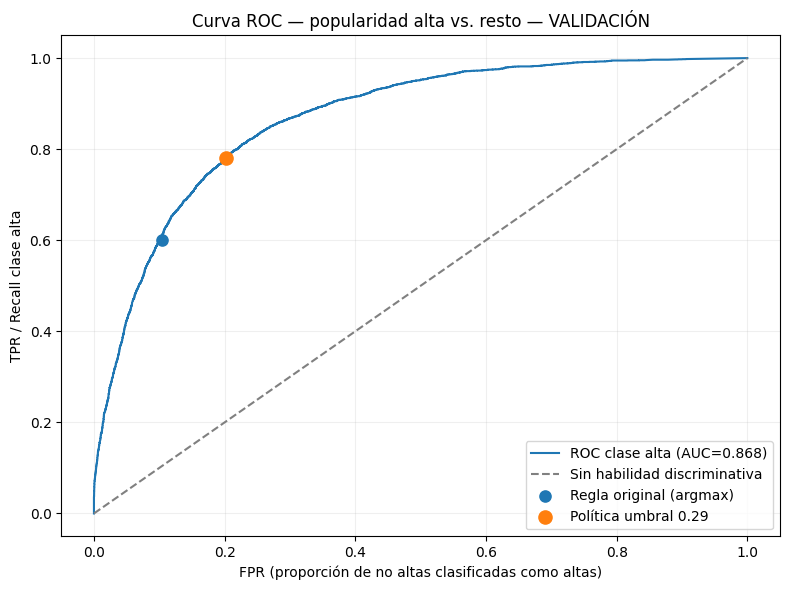

=== COMPARACIÓN EN TEST (SIN RETOQUE DEL UMBRAL) ===


,VP,FP,FN,VN,Recall alta,FPR,Precision alta
RF optimizado · argmax,2564.0,1404.0,1678.0,12303.0,0.6044,0.1024,0.6462
RF optimizado · umbral elegido en validación,3281.0,2729.0,961.0,10978.0,0.7735,0.1991,0.5459


F1 macro argmax: 0.7007
F1 macro ajustado: 0.6841


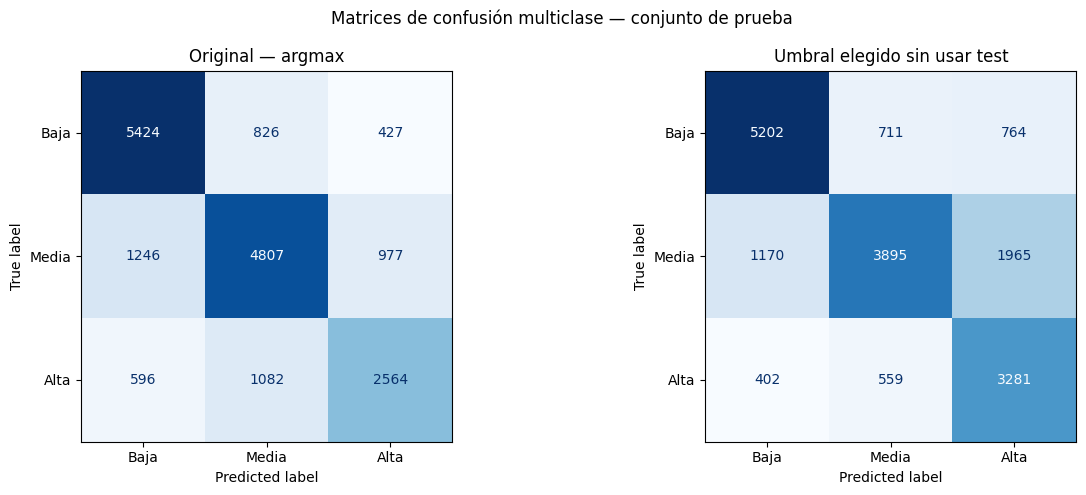

Cambio en falsos negativos de clase alta (ajustada - original): -717
Cambio en falsos positivos: 1325


In [ ]:
"""Selecciona un umbral de alerta para la clase 2 usando una partición de validación separada.

1) Reserva 20% de X_train para validación (sin tocar X_test).
2) Ajusta un CLON del Random Forest ganador en el 80% restante.
3) Traza ROC uno-contra-resto para popularidad alta (=2).
4) Busca menor tasa de falsos negativos con presupuesto de falsos
   positivos: FPR como máximo +0.10 frente a la regla argmax validada.
5) Aplica el umbral congelado al Random Forest ya ajustado en todo train,
   y compara matrices de confusión 3x3 y métricas en test UNA sola vez.

No se vuelve a seleccionar el umbral usando las etiquetas de X_test.
Los hiperparámetros del RF ya se eligieron con CV sobre X_train completo:
esta validación se separa del ajuste del clon, pero NO es independiente de
la selección previa de hiperparámetros. Para auditoría rigurosa de umbrales,
reservar validación antes del tuning o emplear validación anidada.
Los resultados deben recalcularse tras cambiar la codificación.
"""

# Validación separada del entrenamiento, manteniendo proporciones de las 3 clases.
X_train_umbral, X_val_umbral, y_train_umbral, y_val_umbral = train_test_split(
    X_train, y_train, test_size=0.20, random_state=2026, stratify=y_train
)
modelo_validacion_umbral = clone(rf_optimizado)
modelo_validacion_umbral.fit(X_train_umbral, y_train_umbral)

clases_val = modelo_validacion_umbral.classes_
indice_alta = int(np.flatnonzero(clases_val == 2)[0])
probabilidades_val = modelo_validacion_umbral.predict_proba(X_val_umbral)
p_alta_val = probabilidades_val[:, indice_alta]
y_alta_val = (np.asarray(y_val_umbral) == 2).astype(int)

# Predicción original de 3 clases: argmax de probabilidades.
pred_original_val = modelo_validacion_umbral.predict(X_val_umbral)

def prediccion_con_umbral(probabilidades, clases, umbral_alta, clase_alta=2):
    """Prioriza clase alta al superar umbral y conserva 0/1 en otro caso."""
    clases = np.asarray(clases)
    indice = int(np.flatnonzero(clases == clase_alta)[0])
    pred = np.asarray(clases)[np.argmax(probabilidades, axis=1)].copy()
    prioriza_alta = probabilidades[:, indice] >= umbral_alta
    # Si no se selecciona clase alta, se elige entre las otras clases.
    prob_otras = probabilidades.copy()
    prob_otras[:, indice] = -np.inf
    pred[~prioriza_alta] = clases[np.argmax(prob_otras[~prioriza_alta], axis=1)]
    pred[prioriza_alta] = clase_alta
    return pred

def tasas_alerta(y_real, predicciones):
    """TP, FP, FN y TN de la clase alta contra el resto."""
    real = np.asarray(y_real) == 2
    elegido = np.asarray(predicciones) == 2
    tp = int(np.sum(real & elegido))
    fp = int(np.sum(~real & elegido))
    fn = int(np.sum(real & ~elegido))
    tn = int(np.sum(~real & ~elegido))
    return {'VP': tp, 'FP': fp, 'FN': fn, 'VN': tn,
            'Recall alta': tp / (tp + fn) if (tp + fn) else 0.0,
            'FPR': fp / (fp + tn) if (fp + tn) else 0.0,
            'Precision alta': tp / (tp + fp) if (tp + fp) else 0.0}

base_val = tasas_alerta(y_val_umbral, pred_original_val)
limite_fpr = min(1.0, base_val['FPR'] + 0.10)  # presupuesto explícito de FP

# Se incluye un rango amplio para poder acercarse a la frontera comercial.
filas_umbral = []
for t in np.round(np.linspace(0.05, 0.50, 91), 4):
    pred_t = prediccion_con_umbral(probabilidades_val, clases_val, t)
    tasas_t = tasas_alerta(y_val_umbral, pred_t)
    filas_umbral.append({'Umbral': float(t), **tasas_t})
resultados_umbral = pd.DataFrame(filas_umbral)

# Solo se aceptan configuraciones que no aumenten FN respecto del argmax
# y respeten el límite de falsos positivos por unidad negativa.
candidatos = resultados_umbral.loc[
    (resultados_umbral['FN'] <= base_val['FN']) &
    (resultados_umbral['FPR'] <= limite_fpr)
].copy()
if candidatos.empty:
    # Esquema conservador: si la restricción es imposible, no se modifica
    # la política original (umbral=None => predicción argmax de 3 clases).
    umbral_seleccionado = None
    print('Ningún umbral cumple el presupuesto de FPR; se conserva argmax.')
else:
    # Primario: minimizar falsos negativos; desempate: reducir falsos positivos.
    candidatos = candidatos.sort_values(['FN', 'FP', 'Umbral'], ascending=[True, True, False])
    umbral_seleccionado = float(candidatos.iloc[0]['Umbral'])
    print(f'Umbral seleccionado con VALIDACIÓN: {umbral_seleccionado:.3f}')

# ROC solo clase alta vs. resto (en clasificación multiclase).
fpr_roc, tpr_roc, umbrales_roc = roc_curve(y_alta_val, p_alta_val)
auc_alta_val = roc_auc_score(y_alta_val, p_alta_val)
plt.figure(figsize=(8, 6))
plt.plot(fpr_roc, tpr_roc, label=f'ROC clase alta (AUC={auc_alta_val:.3f})')
plt.plot([0, 1], [0, 1], '--', color='gray', label='Sin habilidad discriminativa')
plt.scatter(base_val['FPR'], base_val['Recall alta'], s=65,
            label='Regla original (argmax)', zorder=3)
if umbral_seleccionado is not None:
    val_ajustado = tasas_alerta(y_val_umbral, prediccion_con_umbral(
        probabilidades_val, clases_val, umbral_seleccionado))
    plt.scatter(val_ajustado['FPR'], val_ajustado['Recall alta'], s=90,
                label=f'Política umbral {umbral_seleccionado:.2f}', zorder=3)
plt.xlabel('FPR (proporción de no altas clasificadas como altas)')
plt.ylabel('TPR / Recall clase alta')
plt.title('Curva ROC — popularidad alta vs. resto — VALIDACIÓN')
plt.grid(alpha=0.2)
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

# PRUEBA: el umbral procede SOLO de validación. No usar y_test para elegirlo.
probabilidades_test = rf_optimizado.predict_proba(X_test)
y_pred_umbral_test = (rf_optimizado.predict(X_test) if umbral_seleccionado is None
    else prediccion_con_umbral(probabilidades_test, rf_optimizado.classes_, umbral_seleccionado))

metricas_original_test = tasas_alerta(y_test, y_pred_rf_opt)
metricas_umbral_test = tasas_alerta(y_test, y_pred_umbral_test)
tabla_umbral_test = pd.DataFrame(
    {'RF optimizado · argmax': metricas_original_test,
     'RF optimizado · umbral elegido en validación': metricas_umbral_test}
).T
print('=== COMPARACIÓN EN TEST (SIN RETOQUE DEL UMBRAL) ===')
display(tabla_umbral_test.round(4))
print('F1 macro argmax:', round(f1_score(y_test, y_pred_rf_opt, average='macro'), 4))
print('F1 macro ajustado:', round(f1_score(y_test, y_pred_umbral_test, average='macro'), 4))

fig, ejes = plt.subplots(1, 2, figsize=(13, 5))
for eje, pred, titulo in [
    (ejes[0], y_pred_rf_opt, 'Original — argmax'),
    (ejes[1], y_pred_umbral_test, 'Umbral elegido sin usar test')
]:
    ConfusionMatrixDisplay.from_predictions(
        y_test, pred, labels=[0, 1, 2],
        display_labels=['Baja', 'Media', 'Alta'], cmap='Blues',
        values_format='d', colorbar=False, ax=eje
    )
    eje.set_title(titulo)
fig.suptitle('Matrices de confusión multiclase — conjunto de prueba')
plt.tight_layout()
plt.show()

print('Cambio en falsos negativos de clase alta (ajustada - original):',
      metricas_umbral_test['FN'] - metricas_original_test['FN'])
print('Cambio en falsos positivos:',
      metricas_umbral_test['FP'] - metricas_original_test['FP'])


### 5.19 Rúbrica IE9/IE10 · aporte del ensamble

Cuantificar F1 macro de árbol individual frente a Random Forest y el efecto de la búsqueda de hiperparámetros.


,Familia,F1 macro
Modelo,,
Decision Tree base,Individual,0.6114
Decision Tree optimizado,Individual + tuning,0.6435
Random Forest base,Bagging,0.6977
Random Forest optimizado,Bagging + tuning,0.7007


Aporte RF base vs Árbol base:  0.0863
Aporte tuning RF:  0.003


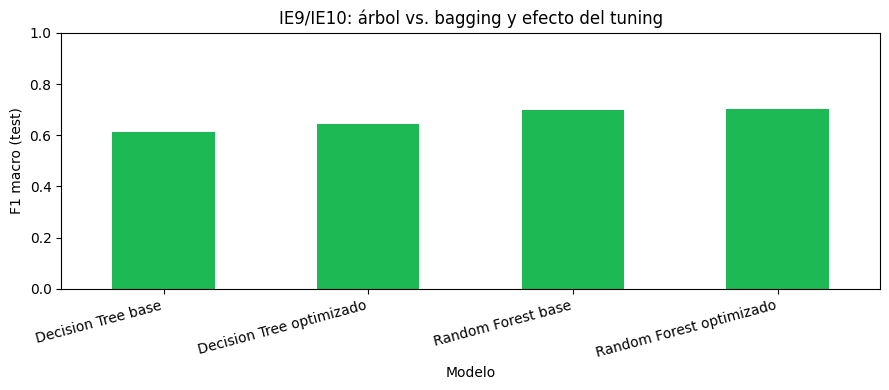

Mejor GridSearch árbol: {'classifier__criterion': 'entropy', 'classifier__max_depth': 8, 'classifier__min_samples_leaf': 1, 'classifier__min_samples_split': 2}
Mejor RandomizedSearch RF: {'classifier__n_estimators': 150, 'classifier__min_samples_split': 2, 'classifier__min_samples_leaf': 2, 'classifier__max_features': 0.5, 'classifier__max_depth': None, 'classifier__class_weight': 'balanced'}


In [ ]:
"""Cuantifica mejoras en F1 macro y el efecto de hiperparámetros.

Usa predicciones y pipelines YA entrenados, sin volver a ajustar.
Resultados comparables: mismos X_test/y_test y misma media macro por clase.
"""
comparativa_ie9_ie10 = pd.DataFrame([
    {'Modelo':'Decision Tree base','Familia':'Individual','F1 macro': f1_score(y_test,y_pred_base,average='macro')},
    {'Modelo':'Decision Tree optimizado','Familia':'Individual + tuning','F1 macro': f1_score(y_test,y_pred_opt,average='macro')},
    {'Modelo':'Random Forest base','Familia':'Bagging','F1 macro': f1_score(y_test,y_pred_rf_base,average='macro')},
    {'Modelo':'Random Forest optimizado','Familia':'Bagging + tuning','F1 macro': f1_score(y_test,y_pred_rf_opt,average='macro')},
]).set_index('Modelo')
display(comparativa_ie9_ie10.round(4))
print('Aporte RF base vs Árbol base: ',round(comparativa_ie9_ie10.loc['Random Forest base','F1 macro']-comparativa_ie9_ie10.loc['Decision Tree base','F1 macro'],4))
print('Aporte tuning RF: ',round(comparativa_ie9_ie10.loc['Random Forest optimizado','F1 macro']-comparativa_ie9_ie10.loc['Random Forest base','F1 macro'],4))
ax = comparativa_ie9_ie10['F1 macro'].plot.bar(figsize=(9,4),ylim=(0,1),color='#1DB954')
ax.set_title('IE9/IE10: árbol vs. bagging y efecto del tuning')
ax.set_ylabel('F1 macro (test)')
plt.xticks(rotation=15,ha='right'); plt.tight_layout(); plt.show()
print('Mejor GridSearch árbol:',grid_search.best_params_)
print('Mejor RandomizedSearch RF:',random_search_rf.best_params_)

### 5.20 Rúbrica IE11 · validación cruzada y generalización

Se conserva la CV sobre Train. **La CV posterior al tuning no es totalmente independiente de la búsqueda**, por lo que una CV anidada o un Test final adicional sería más rigurosa.


In [37]:
"""Compara estabilidad train/CV/test de los dos modelos Random Forest.

La CV estratificada se ajusta SOLO en entrenamiento con 3 pliegues; el test
permanece aparte. Es una segunda comprobación, no una búsqueda de parámetros.
Nota: la selección previa de hiperparámetros ya usó CV en train, por lo que
la CV posterior no es un estimador completamente independiente del tuning.
"""
cv_auditoria = StratifiedKFold(n_splits=3,shuffle=True,random_state=142)
filas_cv_clasificacion=[]
for nombre, estimador, pred_test in [
    ('Random Forest base',rf_base,y_pred_rf_base),
    ('Random Forest optimizado',rf_optimizado,y_pred_rf_opt),
]:
    cv_result = cross_validate(
        clone(estimador), X_train, y_train,
        scoring={'f1_macro':'f1_macro','accuracy':'accuracy'},
        cv=cv_auditoria, n_jobs=1, return_train_score=True,
        error_score='raise'
    )
    filas_cv_clasificacion.append({
        'Modelo':nombre,
        'CV F1 media':np.mean(cv_result['test_f1_macro']),
        'CV F1 desviación':np.std(cv_result['test_f1_macro'],ddof=1),
        'Train CV F1 media':np.mean(cv_result['train_f1_macro']),
        'Test F1 macro':f1_score(y_test,pred_test,average='macro'),
        'Brecha TrainCV-CV':np.mean(cv_result['train_f1_macro'])-np.mean(cv_result['test_f1_macro'])
    })
cv_clasificacion = pd.DataFrame(filas_cv_clasificacion)
display(cv_clasificacion.round(4))

,Modelo,CV F1 media,CV F1 desviación,Train CV F1 media,Test F1 macro,Brecha TrainCV-CV
0,Random Forest base,0.6853,0.0066,0.9819,0.6977,0.2965
1,Random Forest optimizado,0.6885,0.0073,0.9493,0.7007,0.2608


### 5.21 Comparación económica simulada · modelos base y optimizado

Son **escenarios hipotéticos en CLP**, no utilidades observadas de la plataforma. Los falsos positivos representan selecciones que podrían consumir presupuesto.


In [38]:
"""Mide el costo de los errores para identificar canciones de clase alta (=2).

Calcula el conteo REAL de verdaderos positivos y falsos positivos.
Los montos CLP son ESCENARIOS hipotéticos, no ingresos reales ni efecto
causal de la promoción. Beneficio neto = VP * valor supuesto - promociones
* costo supuesto. Falsos negativos indican oportunidad no capturada.
"""
def matriz_economica_alta(y_verdadera, y_predicha, valor_exito=50000, costo_promocion=20000):
    """Resume TP/FP/FN y utilidad hipotética para la clase 2 (50-100)."""
    y_real = np.asarray(y_verdadera) == 2
    y_sel = np.asarray(y_predicha) == 2
    tp=int(np.sum(y_real & y_sel)); fp=int(np.sum(~y_real & y_sel))
    fn=int(np.sum(y_real & ~y_sel)); seleccionadas=tp+fp
    ingreso_supuesto = tp*valor_exito
    inversion_supuesta = seleccionadas*costo_promocion
    return {'VP alta':tp,'FP alta':fp,'FN alta':fn,
            'Promociones':seleccionadas,'Ingreso supuesto CLP':ingreso_supuesto,
            'Costo supuesto CLP':inversion_supuesta,
            'Beneficio neto supuesto CLP':ingreso_supuesto-inversion_supuesta,
            'ROI supuesto %':100*(ingreso_supuesto-inversion_supuesta)/inversion_supuesta if inversion_supuesta else np.nan}
comparacion_economica = pd.DataFrame({
    'RF base': matriz_economica_alta(y_test,y_pred_rf_base),
    'RF optimizado': matriz_economica_alta(y_test,y_pred_rf_opt)
}).T
display(comparacion_economica.round(2))
print('Beneficio incremental simulado, optimizado - base (CLP):',
    comparacion_economica.loc['RF optimizado','Beneficio neto supuesto CLP']-
    comparacion_economica.loc['RF base','Beneficio neto supuesto CLP'])

,VP alta,FP alta,FN alta,Promociones,Ingreso supuesto CLP,Costo supuesto CLP,Beneficio neto supuesto CLP,ROI supuesto %
RF base,2395.0,1192.0,1847.0,3587.0,119750000.0,71740000.0,48010000.0,66.92
RF optimizado,2564.0,1404.0,1678.0,3968.0,128200000.0,79360000.0,48840000.0,61.54


Beneficio incremental simulado, optimizado - base (CLP): 830000.0


### 5.22 Impacto económico simulado · política de umbral

El umbral encuentra más canciones altas, pero también agrega selecciones costosas. En el escenario ilustrativo guardado el resultado neto disminuye al aplicar ese umbral; no se recomienda sin validar costo/beneficio real.


In [39]:
"""Cuantifica el intercambio económico al cambiar umbral para la clase alta.

Se evalúa el mismo conjunto de prueba con las dos reglas; el umbral fue
seleccionado en validación. Los montos son supuestos, no ingresos reales.
"""
comparacion_umbral_economica = pd.DataFrame({
    'RF optimizado · argmax': matriz_economica_alta(y_test, y_pred_rf_opt),
    'RF optimizado · umbral de validación': matriz_economica_alta(y_test, y_pred_umbral_test)
}).T
display(comparacion_umbral_economica.round(2))
print('No seleccionar ni reajustar el umbral usando estas cifras de TEST.')


,VP alta,FP alta,FN alta,Promociones,Ingreso supuesto CLP,Costo supuesto CLP,Beneficio neto supuesto CLP,ROI supuesto %
RF optimizado · argmax,2564.0,1404.0,1678.0,3968.0,128200000.0,79360000.0,48840000.0,61.54
RF optimizado · umbral de validación,3281.0,2729.0,961.0,6010.0,164050000.0,120200000.0,43850000.0,36.48


No seleccionar ni reajustar el umbral usando estas cifras de TEST.


### 5.23 Precision@K · presupuesto de selección fijo

Top-K permite comparar políticas cuando el equipo solo puede revisar o impulsar K canciones, reduciendo el problema del distinto volumen de alertas.


In [40]:
"""Compara RF base y optimizado bajo el mismo presupuesto de K canciones.

En lugar de seleccionar todas las predicciones altas, ordena por la
probabilidad de clase alta (clase 2). Precision@K y Lift@K se calculan en
test; NO representan retornos monetarios ni rendimientos futuros probados.
"""
clase_objetivo = 2
prob_rf_base = rf_base.predict_proba(X_test)[:,list(rf_base.classes_).index(clase_objetivo)]
prob_rf_opt = rf_optimizado.predict_proba(X_test)[:,list(rf_optimizado.classes_).index(clase_objetivo)]
real_alta_test = (np.asarray(y_test)==clase_objetivo).astype(int)
prevalencia_alta = real_alta_test.mean()
filas_top_k=[]
for nombre, proba in [('Random Forest base',prob_rf_base),('Random Forest optimizado',prob_rf_opt)]:
    orden = np.argsort(-proba,kind='stable')
    for k in [250,500,1000,2500]:
        k=min(k,len(y_test))
        exitos=int(real_alta_test[orden[:k]].sum())
        prec=exitos/k
        filas_top_k.append({'Modelo':nombre,'K':k,'Hits reales en Top-K':exitos,
                            'Precision@K':prec,'Lift@K':prec/prevalencia_alta})
tabla_topk=pd.DataFrame(filas_top_k)
display(tabla_topk.round(3))
print('Prevalencia real de clase alta en TEST:',round(prevalencia_alta,4))

,Modelo,K,Hits reales en Top-K,Precision@K,Lift@K
0,Random Forest base,250,236,0.944,3.994
1,Random Forest base,500,442,0.884,3.740
2,Random Forest base,1000,819,0.819,3.465
3,Random Forest base,2500,1829,0.732,3.096
4,Random Forest optimizado,250,237,0.948,4.011
5,Random Forest optimizado,500,452,0.904,3.825
6,Random Forest optimizado,1000,822,0.822,3.478
7,Random Forest optimizado,2500,1841,0.736,3.116


Prevalencia real de clase alta en TEST: 0.2363


### 5.24 Escenarios conservador, base y optimista

Los resultados dependen de valores asignados por supuesto y **no justifican un retorno financiero real**.


In [41]:
"""Escenarios económicos y punto de equilibrio incremental sin datos inventados.

Los conteos provienen de las predicciones sobre test. Solo cambian los
supuestos de beneficio por acierto y costo de promoción. Una decisión real
requiere validar efecto incremental mediante campaña o experimento A/B.
"""
matriz_base = matriz_economica_alta(y_test,y_pred_rf_base)
matriz_optimizada = matriz_economica_alta(y_test,y_pred_rf_opt)
delta_vp=matriz_optimizada['VP alta']-matriz_base['VP alta']
delta_prom=matriz_optimizada['Promociones']-matriz_base['Promociones']
escenarios = [('Conservador',20000,20000),('Base',50000,20000),('Optimista',80000,15000)]
resumen_escenarios=[]
for nombre,valor_hit,costo in escenarios:
    utilidad_delta=delta_vp*valor_hit-delta_prom*costo
    resumen_escenarios.append({'Escenario':nombre,'Beneficio por hit CLP (supuesto)':valor_hit,
        'Costo por promoción CLP (supuesto)':costo,'Beneficio incremental simulado CLP':utilidad_delta})
df_escenarios=pd.DataFrame(resumen_escenarios)
display(df_escenarios)
print(f'Umbral de equilibrio: valor supuesto por hit adicional > {delta_prom/delta_vp:.2f} veces el costo por promoción' if delta_vp>0 else 'El optimizado no recupera más hits.')

,Escenario,Beneficio por hit CLP (supuesto),Costo por promoción CLP (supuesto),Beneficio incremental simulado CLP
0,Conservador,20000,20000,-4240000
1,Base,50000,20000,830000
2,Optimista,80000,15000,7805000


Umbral de equilibrio: valor supuesto por hit adicional > 2.25 veces el costo por promoción


## 5.25 Hallazgos de cada segmento de popularidad y acciones de valor compartido

**Importante:** las categorías **baja, media y alta** no representan gustos o personalidades de usuarios. Son rangos del puntaje histórico `popularity`. Las acciones siguientes son **hipótesis de negocio** que deben pilotearse, no predicciones de impacto causal.

| Segmento (datos observados) | ¿Cómo se interpreta? | Plan de acción para Spotify/equipo editorial | Beneficio para oyentes y artistas | Beneficio esperado para el negocio (a validar) |
|---|---|---|---|---|
| **Baja · 0–24** — 33.385 canciones (**37,20 %**) | Canciones con menor exposición/popularidad observada; **no** necesariamente de menor calidad. | Crear circuitos de descubrimiento y recomendaciones editoriales de nicho; reservar una proporción de espacios para emergentes, con filtros de adecuación musical. | Oyentes descubren repertorio menos conocido; artistas obtienen oportunidades de exposición. | Mayor diversidad y cobertura del catálogo, medibles mediante nuevos artistas escuchados, guardados y retención. |
| **Media · 25–49** — 35.147 canciones (**39,16 %**) | Canciones con popularidad intermedia; puede haber repertorio afín a públicos concretos que aún no se conoce masivamente. | Probar playlists temáticas, recomendaciones contextualizadas y experimentos A/B de exposición a audiencias compatibles. | Oyentes encuentran novedades cercanas a sus intereses; artistas acceden a descubrimiento relevante. | Medir guardados, repeticiones, finalización y avance de descubrimiento sin asumir que subirán automáticamente de categoría. |
| **Alta · 50–100** — 21.209 canciones (**23,63 %**) | Canciones con mayor puntaje de popularidad histórico; son el objetivo prioritario de la detección de clase alta. | Priorizar revisión editorial con probabilidades calibradas o **Top-K** cuando el presupuesto es limitado; balancear éxitos con diversidad. | Oyentes acceden más fácilmente a canciones conocidas y relevantes; artistas obtienen canales eficientes de distribución. | Selección con menor desperdicio de recursos, monitorizando Precision@K, falsos positivos y resultados incrementales. |

### ¿Cómo se benefician mutuamente?

La hipótesis de valor compartido es **mejor pertinencia y descubrimiento para el oyente** junto con **mayor interacción de calidad y diversidad de catálogo para la plataforma**, creando a su vez exposición razonable para artistas. En la práctica se debe comparar contra una experiencia de control, medir *skip*, finalización, guardados, nuevos artistas descubiertos y costos reales de curaduría, además de revisar si ciertos géneros o artistas quedan injustamente relegados.

**Evitar la confusión conceptual:** en la matriz de confusión, una predicción errónea es un problema de clasificación, **no** un juicio sobre la calidad de la canción. Clasificar una canción de baja popularidad como alta podría consumir recursos; no implica que promover esa canción sea perjudicial.


## 5.26 Conclusión enfocada en el negocio

**Resultado técnico del archivo:** con Target Encoding para género y One-Hot para otras categorías, el **Random Forest optimizado** fue el mejor por F1 macro de prueba entre los modelos evaluados aquí (**0,7007**), por encima del árbol optimizado (**0,6435**). Su F1 Train (**0,9504**) frente a Test (**0,7007**) evidencia que **todavía hay sobreajuste**. La validación cruzada del Random Forest optimizado dio un F1 macro medio de **0,6885** en la auditoría guardada.

**Decisión comercial propuesta:** usar el ensamble como **herramienta de priorización**, no como árbitro único de exposición musical. Para identificar más canciones altas, el umbral de validación aumenta el recall de **0,6044 a 0,7735**, pero eleva los falsos positivos de **1.404 a 2.729** en Test. Por ello conviene priorizar **Precision** bajo presupuesto fijo o experimentar con el umbral según el costo real por campaña.

**Beneficio mutuo plausible:** un catálogo mejor organizado podría favorecer descubrimiento, diversidad y adecuación de playlists para los oyentes y mayor eficiencia de selección para la plataforma y los artistas. Estos efectos **no están demostrados por las métricas de clasificación**: exigen pilotos A/B con guardados, saltos, finalización, cobertura de artistas y costos efectivamente medidos.

**Límites:** popularidad histórica puede reflejar sesgo de exposición; `keep='first'` pierde géneros secundarios; Target Encoding no supera necesariamente a One-Hot; y el ajuste de umbral no es completamente independiente del tuning previo. No se informa incremento de ingresos reales.


---
# Fase 6 · Despliegue y entrega de artefactos

El notebook guarda **pipelines completos** (preprocesamiento + clasificador) en `joblib`, hiperparámetros en JSON, y tablas comparativas para la presentación. **Exportar no equivale a tener una aplicación en producción**: para desplegar se requieren un esquema de variables fijo, monitoreo de deriva, control de versiones de datos, revisión humana y evaluación periódica de sesgos/impacto de negocio.

**Siguiente paso recomendado:** piloto de curaduría Top-K, medir calidad de exposición y evaluar las tres categorías sin penalizar automáticamente artistas nuevos.


### 6.1 Validación de pipelines antes de exportar


In [42]:
# PASO 2: IDENTIFICAR Y VALIDAR LOS MODELOS
# Se exportan los pipelines completos para conservar
# la codificación de variables y el clasificador entrenado.

modelos_exportar = {
    "decision_tree_multiclase_base": modelo_base,
    "decision_tree_multiclase_optimizado": modelo_optimizado,
    "random_forest_multiclase_base": rf_base,
    "random_forest_multiclase_optimizado": rf_optimizado
}

# Comprobar todos los modelos antes de comenzar la exportación
for nombre, pipeline in modelos_exportar.items():
    check_is_fitted(pipeline.named_steps["classifier"])
    print(f"Modelo entrenado: {nombre}")

# Carpeta de destino
carpeta_exportacion = Path("modelos_clasificacion_spotify")
carpeta_exportacion.mkdir(parents=True, exist_ok=True)

Modelo entrenado: decision_tree_multiclase_base
Modelo entrenado: decision_tree_multiclase_optimizado
Modelo entrenado: random_forest_multiclase_base
Modelo entrenado: random_forest_multiclase_optimizado


### 6.2 Guardar clasificadores e hiperparámetros


In [43]:
# PASO 3: EXPORTAR MODELOS E HIPERPARÁMETROS
# .joblib: pipeline entrenado y listo para realizar predicciones.
# .json: configuración del clasificador, fácil de consultar.

for nombre, pipeline in modelos_exportar.items():

    # 1. Guardar el pipeline completo
    ruta_modelo = carpeta_exportacion / f"{nombre}.joblib"

    joblib.dump(
        pipeline,
        ruta_modelo,
        compress=3
    )

    # 2. Obtener los hiperparámetros del clasificador
    hiperparametros = (
        pipeline.named_steps["classifier"]
        .get_params(deep=False)
    )

    # 3. Guardar los hiperparámetros
    ruta_parametros = (
        carpeta_exportacion / f"{nombre}_hiperparametros.json"
    )

    with ruta_parametros.open("w", encoding="utf-8") as archivo:
        json.dump(
            hiperparametros,
            archivo,
            indent=4,
            ensure_ascii=False
        )

    print(f"\nExportado: {ruta_modelo}")
    print(f"Configuración: {ruta_parametros}")

print("\nExportación completada.")


Exportado: modelos_clasificacion_spotify/decision_tree_multiclase_base.joblib
Configuración: modelos_clasificacion_spotify/decision_tree_multiclase_base_hiperparametros.json

Exportado: modelos_clasificacion_spotify/decision_tree_multiclase_optimizado.joblib
Configuración: modelos_clasificacion_spotify/decision_tree_multiclase_optimizado_hiperparametros.json

Exportado: modelos_clasificacion_spotify/random_forest_multiclase_base.joblib
Configuración: modelos_clasificacion_spotify/random_forest_multiclase_base_hiperparametros.json

Exportado: modelos_clasificacion_spotify/random_forest_multiclase_optimizado.joblib
Configuración: modelos_clasificacion_spotify/random_forest_multiclase_optimizado_hiperparametros.json

Exportación completada.


### 6.3 Exportar evidencia


In [44]:
"""Exporta resultados para el README.

Los archivos CSV incluyen métricas reales y escenarios hipotéticos separados.
No altera los modelos ni reentrena ni presenta simulaciones como ganancias.
"""
for nombre,tabla in {
    'ie9_ie10_comparacion_clasificacion.csv':comparativa_ie9_ie10.reset_index(),
    'ie11_validacion_clasificacion.csv':cv_clasificacion,
    'ie12_impacto_economico_hipotetico.csv':comparacion_economica.reset_index().rename(columns={'index':'Modelo'}),
    'ie12_topk_clasificacion.csv':tabla_topk,
    'ie12_escenarios_hipoteticos.csv':df_escenarios,
    'ie11_umbral_roc_test.csv':tabla_umbral_test.reset_index().rename(columns={'index':'Politica'}),
    'ie12_escenarios_umbral.csv':comparacion_umbral_economica.reset_index().rename(columns={'index':'Politica'}),
}.items():
    ruta=carpeta_exportacion/nombre
    tabla.to_csv(ruta,index=False)
    print('Evidencia exportada:',ruta)


Evidencia exportada: modelos_clasificacion_spotify/ie9_ie10_comparacion_clasificacion.csv
Evidencia exportada: modelos_clasificacion_spotify/ie11_validacion_clasificacion.csv
Evidencia exportada: modelos_clasificacion_spotify/ie12_impacto_economico_hipotetico.csv
Evidencia exportada: modelos_clasificacion_spotify/ie12_topk_clasificacion.csv
Evidencia exportada: modelos_clasificacion_spotify/ie12_escenarios_hipoteticos.csv
Evidencia exportada: modelos_clasificacion_spotify/ie11_umbral_roc_test.csv
Evidencia exportada: modelos_clasificacion_spotify/ie12_escenarios_umbral.csv


### 6.4 Empaquetar archivos para Google Colab y Jupyter

La descarga se ejecuta únicamente si la biblioteca de Colab estaba disponible desde la **celda única de imports**. En Jupyter local se deja el ZIP en disco.


In [45]:
# PASO 4: COMPRIMIR Y DESCARGAR LOS ARCHIVOS

ruta_zip = shutil.make_archive(
    base_name="modelos_clasificacion_spotify",
    format="zip",
    root_dir=str(carpeta_exportacion)
)

print(f"ZIP generado: {ruta_zip}")

# Descarga opcional solo en Google Colab. En Jupyter local el ZIP queda guardado.
if colab_files is not None:
    colab_files.download(ruta_zip)
else:
    print("Archivo generado localmente:", Path(ruta_zip).resolve())

ZIP generado: /content/modelos_clasificacion_spotify.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>